# Does EEG explain what kinematics cannot? — residual KG-GT notebook (Package 2, Phase C, run tag `p2c`)

**Question.** The single-stage models reach Pearson r ≈ 0.89 on the P1 test series, but the output comes from the kinematics and the gated forces: time-shuffling the EEG changes r by −0.003. A per-lift linear analysis suggested that EEG band power explains none of the lift-to-lift magnitude that force does not explain, and that one muscle (Flexor Digitorum, FD) has a series-level amplitude drift that no input explains. This notebook measures the **unique** contribution of the EEG: fit the best kinematics-only model, freeze it, and let an EEG-only model predict what is left.

## The two stages

**Stage K — kinematics-only model.** The same KG-GT architecture, called with `use_eeg=False` (wrapper `KinOnly`): the EEG encoder is not run and its output is replaced by zeros. The node projection is a linear layer, so the muscle-node embeddings are then its **bias** only — one learned vector per muscle, the same at every time step. The kinematics-guided GAT (static + kinematic edge bias), the kinematic skip highway, the per-muscle decoder and the lag alignment work as usual. No gradient reaches the encoder. It is trained with the composite loss of `CONFIG` with the EEG-specific parts off (`w_eeg_only` = 0, `kin_dropout` = 0, no EEG-only auxiliary output), early stopping on the smoothed validation loss, then the best checkpoint is loaded and the model is frozen.

**Stage E — EEG residual model.** For every batch the target is the residual in normalised units, `res = emg_z − kin_pred_z`, with `kin_pred_z` from the frozen Stage-K model (eval mode, no gradient). The model is the same architecture with both kinematic pathways off (`use_kin=False`, wrapper `EEGOnly`): band-power EEG → encoder → node projection → GAT with the static edge bias only → decoder. The regularised encoder and the electrode dropout of `CONFIG` stay on. The residual is signed and has mean ≈ 0, so the envelope-specific loss terms do not apply; the loss is `ResidualLoss` = Huber(δ = 1) + 0.2 · (1 − Pearson r along time, per window and muscle; windows whose residual is constant are skipped). The cell prints the loss of predicting zero residual: a trained model has to be below it on the validation series.

Both stages use `residual.lr`, `residual.early_stop_patience` and their own number of epochs; optimiser, cosine schedule, warm-up, parameter groups (encoder + node projection at lr × 0.1, kin skip at lr / 3), gradient clipping, AMP, batch size and gradient accumulation are the shared `training` keys of `main_p2p.ipynb`.

## What the numbers mean

All numbers are for the **test** series, predicted in 1 s windows through `main.inference` (the same path as the other notebooks). VAF and RMSE are in original EMG units, residual statistics in z units.

| Number | Meaning |
|---|---|
| kin r / VAF / RMSE | the kinematics-only model alone |
| kin + EEG r / VAF / RMSE | kinematics-only prediction + predicted residual |
| ΔVAF, Δr | (kin + EEG) − (kin only); ΔVAF in percentage points. Negative = the EEG model makes the prediction worse |
| res r | Pearson r between predicted and true residual |
| res FVE | fraction of the residual variance explained, 1 − Σ(res − pred)² / Σ(res − mean)²; negative = worse than predicting the mean residual |
| null "shuffle" | the same EEG model, EEG time-shuffled within each window. The window keeps its values, so its mean level survives: this null removes only the timing inside the window |
| null "swap" | the same EEG model, each window fed the EEG of a **different** test window (a random derangement of all test windows: no window keeps its own EEG). EEG statistics stay realistic, but the EEG is unrelated to this window's EMG |
| p | (1 + number of null draws ≥ observed) / (1 + `n_null`), per muscle and for the mean over muscles. With `n_null` = 20 the smallest possible p is 1/21 ≈ 0.048 |
| lift r | per test lift: mean true residual vs mean predicted residual over the hold phase (lift-off + 0.3 s … replace − 0.3 s), then Pearson r across lifts — per series and pooled, with the same for the "swap" null. This is the question whether EEG explains lift-to-lift magnitude left over by the kinematics (FD especially) |
| lift r within | pooled lift r after subtracting each series' mean from both sides. The pooled lift r of two test series can be large because of one between-series offset (two points); this one cannot |

## What would count as evidence

A muscle gets the verdict **"EEG adds unique information"** only if all three hold:

1. ΔVAF > 0 over all test series, **and**
2. p ≤ 0.05 for ΔVAF against the "swap" null, **and**
3. the residual r is > 0 in **both** test series — per lift in both, or per sample in both.

Otherwise the verdict is **"no evidence"**. "No evidence" is not evidence of absence: it means this model, on these test series, did not find a contribution. Five muscles are tested, so one p ≤ 0.05 by chance is not unlikely; a single muscle passing should be read with that in mind.

## Outputs (nothing of an earlier run is overwritten)

| Output | Path |
|---|---|
| Stage K checkpoints | `outputs/checkpoints_residual_p2c/kin_only/{subject}/` (`last.pt` + `best.pt`, resumable) |
| Stage E checkpoints | `outputs/checkpoints_residual_p2c/eeg_residual/{subject}/` |
| Report table | `results/p2c/residual_report.csv` (per muscle + MEAN; per test series and all test series; nulls, p-values, verdict) |
| Per-lift table | `results/p2c/residual_per_lift.csv` (one row per test lift and muscle) |
| Figures | `results/p2c/residual_delta_vaf.png`, `results/p2c/residual_per_lift.png` |
| Training curves saved by `main.plots` | `results/P{id}/main/<config>_p2c/plots/` |

Stage E resumes from its `last.pt`. Its targets depend on the Stage-K model, so if Stage K is trained again, delete the `eeg_residual` folder (or change the run tag) before running Stage E.

## What is the same as `main_p2p.ipynb`

`CONFIG` is that of `main_p2p.ipynb` except `outputs.run_tag` (`p2c`), `training.checkpoint_dir` and the new `residual` block. Same participants and condition-stratified split, same preprocessing and cache (`data/cache_main_stride500_square_pose_force_sg51`, read only), same 128 log band-power EEG inputs (z-scored with the training series, clipped to ±5), same 24 kinematic inputs, same model sizes and loss weights. The helper and pre-processing cells are copied unchanged. This notebook has no interpretability cells.


In [1]:
import torch
import numpy as np
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import copy
from pathlib import Path

# Import from main
from main import (
    get_device, set_seed,
    load_participant, get_split_series,
    series_conditions, stratified_split, describe_split,
    preprocess_eeg, preprocess_eeg_from_config,
    preprocess_emg, preprocess_emg_from_config, EMGNormalizer,
    preprocess_kinematics, preprocess_kinematics_from_config, KinNormalizer,
    extract_kt, extract_kt_raw,
    WAYEEGDataset,
    KGGTModel, build_kg_gt_from_config, CNN1dAligner,
    build_transformer_only_from_config,
    CombinedEMGLoss, CompositeEMGLoss, CCCLoss, PearsonCorrelationLoss, TemporalSmoothnessLoss,
    build_loss_from_config,
    train_model, TrainConfig, TrainResult,
    collect_predictions, compute_metrics, EvalMetrics,
    prepare_batch_factory, save_checkpoint, load_checkpoint,
    print_gpu_info,
    compute_muscle_edge_prior,   # for edge-prior computation (follow-up step)
)

ROOT = Path(".")

In [2]:
set_seed(42)
device = get_device()
torch.backends.cudnn.benchmark = True
print(f"Device: {device}")


Device: cuda


In [3]:
CONFIG = {
    # ── Package 2, Phase C: does EEG explain what kinematics cannot? (run tag "p2c") ──
    # Identical to main_p2p.ipynb's CONFIG except: outputs.run_tag, training.checkpoint_dir
    # and the "residual" block (Stage K = kinematics-only model, Stage E = EEG model on the
    # residual). kin_dropout, w_eeg_only and the EEG-only auxiliary output are switched off
    # per stage in the stage cells, not here.
    # ── Settings inherited from Phase B ──────────────────────────────────────────
    # * EEG input = log band power (preprocessing.eeg_features): 32 electrodes x 4 bands
    #   = 128 features, computed per full series AFTER the cache is read (same cache
    #   folder, not modified), z-scored with TRAIN statistics and clipped to ±5 in prepare_batch
    # * model.kin_dropout 0.3: in training both kinematic pathways are switched off for
    #   30 % of the windows; training.loss.w_eeg_only 0.5: the EEG-only prediction of
    #   every batch gets the same loss terms
    # * smaller EEG encoder (2 layers, 4 heads, d_model 64, dropout 0.3), electrode
    #   dropout 0.2 (model.eeg_channel_dropout / eeg_groups)
    # * outputs.run_tag "p2c": every file this notebook writes goes to a tagged path
    #   (see the block below the dict) → no result or checkpoint of an earlier run is overwritten
    # ── Step 1: magnitude (on top of Package 1) ─────────────────────────────────
    # * gated load / grip force also feed the additive kin skip highway (amplitude path),
    #   not only the GAT edge bias; the velocities of the gated forces are kept as
    #   force-rate inputs → 24 kin features (same 26-column cache, other drop_indices)
    # * loss: asymmetry 1.5, huber_delta 2.5, new active-level term w_height 0.5
    # * stage 2: lr 1e-4 + early stop after 25 epochs without val improvement
    # * stage 1: early stop after 10 epochs without val improvement (stage1_early_stop_patience)
    # * single stage (this notebook): early stop after 20 epochs (single_stage.early_stop_patience)
    # Checkpoints: no need to move aside older folders any more — this run writes to its own
    # tagged folders (training.checkpoint_dir ends in the run tag); the kin input is still 24 features.
    "outputs":{
        "figures_dir": "docs/figure/method1",
        # Tag of THIS run. Every output path is derived from it (RUN_TAG / RESULTS_DIR /
        # tagged_output below, training.checkpoint_dir, the results/P{id}/main/<config>_<tag> plot
        # folder), so the Step-1 and Phase B results and checkpoints are not overwritten by this run.
        # For the next experiment change this tag AND training.checkpoint_dir.
        "run_tag": "p2c",
    },
    "data": {
        "participant": "P1",       
        "data_root": "data/way-eeg/raw",
        "cache_dir": "data/cache_main_stride500_square_pose_force_sg51",  # new folder: hand pose + hand-near-object gated forces (26 cached kin cols)
        # window_size=4000 @ 500 Hz = 8 s window; stride=250 = 0.5 s step
        # chunked transformer: 4000 / chunk_size=500 = 8 chunks of 500 → O(500²) not O(4000²)
        "window_size": 500,
        "stride": 500,
        # latency_shift_ms eliminated: Transformer attention learns asymmetric corticomuscular conduction delay
        "fs_eeg": 500,                   # Hz
        "fs_emg": 4000,                  # Hz (raw); downsampled to fs_eeg after preprocess
        "fs_kin": 500,                   # Hz
        "n_eeg_channels": 32,            # electrodes in the cache; model input = 32 x 4 bands = 128 features (preprocessing.eeg_features)
        "n_emg_channels": 5,
        "n_kin_raw": 36,                 # raw kin cols in hs.kin.sig
        "n_kin_features": 24             # model input: hand pose (10) + gated F_L, F_G (2) + pose velocity (10) + gated F_L, F_G velocity (2)
    },
    "preprocessing": {
        "eeg": {
            "bp_low": 0.5,                  # Hz, bandpass lower bound
            "bp_high": 40.0,                # Hz, bandpass upper bound
            "artifact_method": "ica_auto",  # "asr" | "ica_auto" | "ica_manual"
            "filter_order": 4,
            "notch_freq": 50.0,             # Hz, power-line
            "asr_window_ms": 500,           # ms, ASR sliding window
            "asr_std_thresh": 5.0,          # sigma, ASR rejection threshold
            "delta_low": 0.5,               # Hz, delta-band lower bound
            "delta_high": 40.0,             # Hz, delta-band upper bound
            "use_car": False,
            "use_tkeo": True,
            #"target_channels": ["FC1", "FC2", "C3", "Cz", "C4", "CP1", "CP2", "CP6"]
        },
        # Phase B: EEG model input = log band power instead of the raw waveform. Per electrode and
        # band: zero-phase band-pass → squared Hilbert envelope → zero-phase smoothing at smooth_hz →
        # log (floor 1e-3 x the median). Band-major layout (band0 ch0..31, band1 ch0..31, …), computed
        # on each FULL series after the cache is read (main.eeg_features; the cache keeps the raw EEG).
        # None / absent = raw EEG as before.
        "eeg_features": {"type": "bandpower", "bands": [[4, 8], [8, 13], [13, 30], [30, 40]], "smooth_hz": 5.0},
        "emg": {
            "bp_low": 30.0,              # Hz
            "bp_high": 300.0,            # Hz
            "filter_order": 4,
            "lp_cutoff": 8.0,            # Hz, near-DC → flat-top square-like activation bursts
            "lp_order": 4,               # 8th-order → brick-wall roll-off, flat plateau between bursts
            "downsample_factor": 8,      # 4000 -> 500 Hz
            "envelope_method": "tkeo", # strictly causal full-wave rectification default
            "causal": True,              # strict forward-only causal filtering (no lookahead)
        },
        "kinematics": {
            "include_velocity": True,      # if true, output includes velocity
            "include_acceleration": False, # off: the SG 2nd derivative amplifies marker jitter at rest
            # Object forces count only while the hand is at the object: F_L, F_G are multiplied by a gate
            # (1 while index-object distance <= near_cm, linear ramp to 0 at far_cm, 0.1 s zero-phase
            # smoothing) BEFORE velocities are computed. Loading of the object by someone else while the
            # hand is parked (~28 cm away) is removed. None / absent = forces not gated.
            "gated_force": {"near_cm": 12.0, "far_cm": 20.0, "smooth_s": 0.1},
            "drop_indices": [12, 25],  # = POSE_FORCE_RATE_DROP_INDICES: drop rho_GL and its velocity → 24 = [hand pose 10, F_L_gated, F_G_gated, pose velocity 10, v_F_L_gated, v_F_G_gated]
            "velocity_method": "sg",     # 'sg' (Savitzky-Golay) | 'bw' (Butterworth diff)
            "sg_window": 51,             # SG window length (samples, must be odd); 51 = 102 ms at 500 Hz → less jitter at rest
            "sg_poly": 3,                # SG polynomial order
            "bw_cutoff": 20.0,           # LP cutoff Hz before diff (used when method='bw')
            "bw_order": 4,               # Butterworth order (used when method='bw')
            "normalize": True            # per-feature z-score over training set
        },
    },
    "model": {
        "type": "transformer_regressor",
        # Phase B regularisation of the EEG path (all three are training-only; 0 = off):
        "eeg_channel_dropout": 0.2,   # electrode dropout: a whole electrode (all its bands) is zeroed for the whole window
        "eeg_groups": 4,              # feature columns per electrode = number of bands in preprocessing.eeg_features
        "kin_dropout": 0.3,           # per window: both kinematic pathways (GAT kinematic edge bias + kin skip) off
        "transformer": {              # Phase B: smaller encoder (was 4 layers, 8 heads, d_model 128, d_k/d_v 32, ffn 512, dropout 0.2)
            "n_layers": 2,
            "n_heads": 4,
            "d_model": 64,
            "d_k": 16,
            "d_v": 16,
            "ffn_dim": 256,
            "dropout": 0.3,
            # chunk_size=500 with window_size=4000 → 8 chunks of 500
            # → O(500²)=250K scores per head (not O(4000²)=16M)
            # MUST divide window_size evenly or a RuntimeWarning fires and
            # full O(T²) attention is used (catastrophically slow).
            "chunk_size": 500
        },
        "gat": {
            "n_layers": 2,
            "node_dim": 64,
            "hidden_dim": 64,
            "heads": 4,
            "dropout": 0.2,
            "use_kinematic_guidance": True,
            "kin_gat_dim": 12,             # first 12 kin features (pose 10 + gated F_L, F_G) → GAT edge bias
            "kin_skip_indices": list(range(10, 24)),  # → kin skip highway (adds to the node embeddings = amplitude path): gated F_L, F_G + all 12 velocities
        },
        "decoder": {
            "out_channels": 5            # predicted EMG channels
        }
    },
    "training": {
        "loss": {
            "w_peak":          1.0,     # Peak-weighted MSE weight
            "w_ccc":           0.5,     # Concordance Correlation Coefficient weight (prevents Mean Collapse)
            "w_pearson":       0.2,     # Pearson correlation timing weight
            "w_diff":          0.1,     # First-order temporal smoothness weight
            "w_rest":          0.05,    # Resting baseline L1 penalty
            "w_reg":           0.001,   # GAT EdgePrior KL divergence anchor
            "peak_alpha":      3.0,     # Multiplier for burst tips in PeakMSE
            "asymmetry":       1.5,     # Under-prediction penalty (Package 1: 1.2 — too weak a pull towards burst height; 2.0 before)
            "rest_threshold":  0.15,    # Rest threshold fraction
            "eps":             1e-6,    # Denominator clamp for AMP FP16 numerical stability
            "use_peak_weight": True,    # set False for ablation back to standard MSE
            "w_rest_over":     1.0,     # one-sided squared over-prediction where the target is at rest (baseline recovery)
            "huber_delta":     2.5,     # robust peak-weighted error (z units): squared inside ±2.5, linear outside; None = squared (Package 1: 1.0)
            "channel_weights": "auto",  # per-muscle weights ∝ 1/p95(|z|) of the training targets, mean 1 (computed per subject)
            "w_height":        0.5,     # active-level term: per window/muscle, relative error of the mean level above the window minimum over the non-rest samples (under-prediction × asymmetry, smooth-L1)
            "height_eps":      0.5,     # its denominator floor (z units) so noise-only windows do not give huge relative errors
            "w_eeg_only":      0.5,     # Phase B: EEG-only auxiliary loss — the same terms (no KL) for the prediction with both kinematic pathways off; training only (not part of the val loss)
        },
        # ── optimizer ─────────────────────────────────────────────────────
        "optimizer":   "adamw",   # 'adam' | 'adamw'
        "weight_decay": 0.01,     # AdamW weight decay (ignored for adam); kept at 0.01 (the kin-skip group uses 5x this value)
        # ── scheduler ─────────────────────────────────────────────────────
        "scheduler":   "cosine",  # 'reduce' | 'cosine'
        # reduce-specific
        "lr_patience": 5,
        "lr_factor":   0.5,
        # cosine-specific
        "cosine_t_max":   None,   # None → use max_epochs
        "cosine_eta_min": 1e-6,
        # ── common ────────────────────────────────────────────────────────
        "loss_lambda":  1.0,      # 1.0 = plain MSE; <1.0 enables Soft-DTW (O(T²), DO NOT use at T=4000)
        "stage1_lr": 1e-3,
        "warmup_epochs": 5,
        "stage2_lr": 1e-4,          # two-stage only (unused here)
        # Early stopping (main/training.py): the "best" epoch is the one with the lowest
        # SMOOTHED validation loss = mean of the last 5 epochs' val losses (the raw val loss
        # during the first 4 epochs); best.pt holds the weights of the epoch at which that
        # value was reached, and patience counts epochs without a new smoothed best.
        "stage1_early_stop_patience": 10,   # two-stage only (unused here)
        "stage2_early_stop_patience": 25,   # two-stage only (unused here)
        "transformer_lr_scale": 0.1,
        # batch_size=4 with T=4000 keeps VRAM safe on GTX 1660 Ti (6 GB).
        # effective batch = batch_size * gradient_accumulation_steps = 4 * 8 = 32
        # Tune batch_size up (e.g. 8) if VRAM is available; reduce grad_accum_steps proportionally.
        "batch_size":          32,
        "gradient_accumulation_steps": 2,
        "early_stop_patience": 50,   # shared default (not used by the single stage: single_stage.early_stop_patience)
        "grad_clip_norm":      1.0,
        "stage1_epochs":       75,  # two-stage only (unused here)
        "max_epochs":          200,
        # use_amp=True: enables FP16 mixed precision via torch.autocast + GradScaler.
        # GTX 1660 Ti (sm_75 Turing) has FP16 tensor cores → ~1.5-2x speedup.
        # Requires PyTorch >= 2.0. Set False only if you see NaN losses.
        "use_amp":             True,
        "log_memory_every":    50,
        "losocv": True,           # leave-one-subject-out cross-validation
        "checkpoint_every":     1,
        # ── checkpoints of THIS run (must end in the run tag, checked below the dict) ──
        # Stage K -> <checkpoint_dir>/kin_only/{subject}/, Stage E -> <checkpoint_dir>/eeg_residual/{subject}/
        "checkpoint_dir": "outputs/checkpoints_residual_p2c",
        # ── single_stage: main_p2p.ipynb only (kept so the two CONFIGs stay comparable;
        #    this notebook takes lr / epochs / patience from the "residual" block below) ──
        # The full KG-GT model is trained ONCE, jointly, nothing frozen.
        # Only lr / epochs / patience live here; everything else is the shared key above:
        #   optimizer="adamw", scheduler="cosine" (eta_min 1e-6), warmup_epochs=5,
        #   transformer_lr_scale=0.1 (encoder+node-proj at lr*0.1, as in stage 1),
        #   grad_clip_norm, use_amp, batch_size, gradient_accumulation_steps, seed.
        "single_stage": {
            "lr":     1e-3,     # = stage1_lr (GAT/decoder group; encoder x transformer_lr_scale)
            "epochs": 200,      # = max_epochs
            # epochs without a new best of the SMOOTHED val loss (5-epoch moving average,
            # main/training.py; best.pt is selected on that smoothed value too)
            "early_stop_patience": 25,
        },
        "seed":                42,
    },
    # ── Phase C: the two stages and the evaluation ─────────────────────────────
    "residual": {
        "kin_epochs": 200,           # Stage K (kinematics-only model): max epochs
        "eeg_epochs": 200,           # Stage E (EEG model on the residual): max epochs
        "early_stop_patience": 20,   # both stages: epochs without a new best SMOOTHED val loss
        "lr": 1e-3,                  # both stages (encoder + node projection x transformer_lr_scale)
        "n_null": 20,                # draws per null distribution in the evaluation (smallest p = 1/21)
        "seed": 42,                  # model initialisation of both stages and the null draws
    },
    "dataset": {
        # Keep in sync with data.window_size / data.stride above
        "window_size": 500,
        "stride": 500,
    }
}
# ── Run tag: nothing of an earlier run is overwritten ──────────────────────────
# Every path this notebook writes to is derived from CONFIG["outputs"]["run_tag"]:
#   RESULTS_DIR             results/<tag>/…          reports, tables, summary figures
#   tagged_output(name)     outputs/<name>_<tag>…    interpretability / kin-gate / LOSOCV figures and files
#   training.checkpoint_dir must end in _<tag>        (checked here)
#   main.plots figure folders: results/P{id}/main/<config>_<tag>/plots
RUN_TAG = CONFIG["outputs"]["run_tag"]
assert RUN_TAG, "set CONFIG['outputs']['run_tag']: an untagged run would overwrite older results"
RESULTS_DIR = f"results/{RUN_TAG}"


def tagged_output(name):
    """Folder (or file stem) <name>_<run tag> in the outputs folder: it belongs to this run only."""
    return f"outputs/{name}_{RUN_TAG}"


RESIDUAL_STAGES = ("kin_only", "eeg_residual")


def stage_checkpoint_dir(cfg, stage, subj):
    """Checkpoint folder of one stage and subject: <training.checkpoint_dir>/<stage>/<subj>."""
    assert stage in RESIDUAL_STAGES, stage
    base = cfg["training"]["checkpoint_dir"]
    assert base.endswith("_" + str(cfg["outputs"]["run_tag"])), base
    return f"{base}/{stage}/{subj}"


assert CONFIG["training"]["checkpoint_dir"].endswith("_" + RUN_TAG), \
    "training.checkpoint_dir must end with the run tag, otherwise checkpoints of an older run are overwritten"
assert CONFIG["model"]["eeg_groups"] == len((CONFIG["preprocessing"].get("eeg_features") or {}).get("bands", [0])), \
    "model.eeg_groups must be the number of bands in preprocessing.eeg_features (1 for raw EEG)"
# Plot folders (main.plots.get_dynamic_fig_dir) are keyed on training["lr"] and the run tag:
# use the LR of the two stages (the folder also ends in the run tag, so nothing is shared
# with main.ipynb / main_p2p.ipynb).
CONFIG["training"]["lr"] = CONFIG["residual"]["lr"]
notebook_cfg = copy.deepcopy(CONFIG)

### EMG channel names (true order)

`hs.emg.names` of every `HS_P{p}_S{1..9}.mat` lists the five EMG channels in this order (checked for P1–P12: identical for all participants and series):

| channel | muscle (name in the data files) | label used in this notebook | label in outputs made before this fix |
|---|---|---|---|
| 0 | Anterior Deltoid | AD | "FDI" |
| 1 | Brachoradial (brachioradialis) | BR | "APB" |
| 2 | Flexor Digitorum | FD | "ADM" |
| 3 | Common Extensor Digitorum | ED | "ECR" |
| 4 | First Dorsal Interosseus | FDI | "FCR" |

Every cell now takes the names per subject from `main.dataloader.emg_channel_names(participant, data_dir)`, which reads them from that participant's HS files (and raises if the series of a participant disagree). Earlier versions hard-coded `["FDI", "APB", "ADM", "ECR", "FCR"]`, which is **not** the channel order of the data: figures, tables, CSV files and reports produced before this fix (including cell outputs saved in this notebook that have not been re-run) carry the wrong labels — translate them with the table above. Only the labels were wrong; channel order, data, model and metrics are unchanged.


### Train / val / test split (per participant, condition-stratified)

Each participant has 9 series: 5×**W** (weight varies, surface fixed), 2×**S** (surface varies, weight fixed), 2×**B** (both vary), read from `BlockType` in `P{p}_AllLifts.mat`. Series 7, 8, 9 are always W; series 1–6 hold 2 W + 2 S + 2 B in a participant-specific order.

- **test** = the *later* W and the *later* B among series 1–6 → {W, B}
- **val** = series 9 → {W}
- **train** = the earlier W of 1–6, series 7 and 8, both S series, the *earlier* B → {3 W, 2 S, 1 B}

`WAYEEGDataset` applies this automatically (`stratified_split(p)` / `get_split_series(split, p)`); a missing AllLifts file or a composition other than 5W/2S/2B raises an error. The test series ids therefore differ per participant (no longer fixed to 3 and 4). `describe_split(p)` prints the table.

In [4]:
from main.eeg_features import (
    build_eeg_transform_from_config, fit_feature_stats, clip_fraction,
    eeg_electrode_groups, eeg_band_groups,
)
from main.training import normalized_prepare_batch_factory

EEG_CLIP = 5.0   # EEG features are clipped to ±EEG_CLIP after the z-score (prepare_batch)


def make_preprocess_fn(cfg):
    eeg_cfg = cfg["preprocessing"]["eeg"]
    emg_cfg = cfg["preprocessing"]["emg"]
    kin_cfg = cfg["preprocessing"]["kinematics"]
    def preprocess_fn(series):
        series = dict(series)
        series["eeg"] = preprocess_eeg_from_config(
            series["eeg"],
            float(series["fs_eeg"]),
            eeg_cfg,
            channel_names=series.get("eeg_names"),
        )
        series["emg"] = preprocess_emg_from_config(
            series["emg"],
            float(series["fs_emg"]),
            emg_cfg,
        )
        series["kin"] = preprocess_kinematics_from_config(                                           
              series["kin"],                                                                           
              float(series["fs_kin"]),                                                                 
              kin_cfg,                                                                                 
        ) 
        return series

    return preprocess_fn


def resolve_participants(participant_spec):
    """Resolve participant spec to a list of int IDs.
    
    Accepts:
      "all"        -> [1, 2, ..., 12]
      "P3"         -> [3]
      3            -> [3]
      [1, 2, 3]   -> [1, 2, 3]
      ["P1", "P3"] -> [1, 3]
    """
    ALL_PARTICIPANTS = list(range(1, 13))
    if participant_spec == "all":
        return ALL_PARTICIPANTS
    if isinstance(participant_spec, (list, tuple)):
        return [int(str(p).replace("P", "")) for p in participant_spec]
    # single string like "P2" or int like 2
    return [int(str(participant_spec).replace("P", ""))]


def build_dataset_split(cfg, participants=None, split="train", root_dir=ROOT):
    """Build WAYEEGDataset for the given split.
    
    participants: list of int IDs, or None (uses cfg["data"]["participant"]).
    split: "train" | "val" | "test" | "all" | "stability"
    """
    data_cfg = cfg["data"]
    if participants is None:
        participants = resolve_participants(data_cfg["participant"])
    return WAYEEGDataset(
        data_dir=root_dir / data_cfg["data_root"],
        participants=participants,
        split=split,
        window_size=cfg["dataset"]["window_size"],
        stride=cfg["dataset"]["stride"],
        latency_shift_ms=0.0,
        preprocess_fn=make_preprocess_fn(cfg),
        cache_dir=root_dir / data_cfg["cache_dir"],
        # Phase B: EEG features (log band power) are computed per FULL series right after the
        # cached EEG is loaded — the same transform for train, val and test; the cache keeps the
        # raw EEG and is not modified. None when preprocessing.eeg_features is absent (raw EEG).
        eeg_transform=build_eeg_transform_from_config(cfg["preprocessing"], fs=data_cfg["fs_eeg"]),
    )

# ─────────────────────────────────────────────────────────────────────────────
# Helper utilities (used by both the per-subject loop and LOSOCV loop below)
# ─────────────────────────────────────────────────────────────────────────────

def unique_series_arrays(ds):
    """Return deduplicated (eeg, kin, emg) arrays from a WAYEEGDataset."""
    seen, eegs, kins, emgs = set(), [], [], []
    for eeg_all, kin_all, emg_all, _ in ds._windows:
        key = id(eeg_all)
        if key in seen:
            continue
        seen.add(key)
        eegs.append(eeg_all)
        kins.append(kin_all)
        emgs.append(emg_all)
    return eegs, kins, emgs


def local_prepare_batch_factory(emg_mean, emg_std, kin_mean, kin_std, device,
                                drop_kin_indices=None, eeg_mean=None, eeg_std=None):
    """Return a per-subject prepare_batch closure with frozen normalization stats.

    kin and EMG: z-score with the TRAIN statistics (kin columns in drop_kin_indices removed).
    EEG: with eeg_mean / eeg_std (Phase B, EEG features on) per-feature z-score with the
    TRAIN statistics, then clipped to ±EEG_CLIP; with None the EEG is passed through as
    before. The closure lives in the library (main.training.normalized_prepare_batch_factory);
    every cell — training, evaluation, magnitude, ablation, interpretability — uses this one.
    """
    return normalized_prepare_batch_factory(
        emg_mean, emg_std, kin_mean, kin_std, device,
        drop_kin_indices=drop_kin_indices,
        eeg_mean=eeg_mean, eeg_std=eeg_std, eeg_clip=EEG_CLIP,
    )


def fit_eeg_normalisation(cfg, train_eegs, device, electrode_names=None, verbose=True):
    """EEG feature statistics of the TRAINING series (Phase B).

    Returns (eeg_mean, eeg_std, eeg_groups, eeg_band_groups):
      eeg_mean, eeg_std   (F,) tensors on `device` for local_prepare_batch_factory
      eeg_groups          {electrode: its n_bands columns}  → electrode occlusion / attribution
      eeg_band_groups     {band: its columns}               → per-band attribution
    or (None, None, None, None) when preprocessing.eeg_features is off (raw EEG, not normalised
    here, exactly as before).
    """
    spec = cfg["preprocessing"].get("eeg_features")
    if not spec:
        return None, None, None, None
    bands = spec["bands"]
    n_feat = train_eegs[0].shape[1]
    n_el = n_feat // len(bands)
    assert n_el * len(bands) == n_feat, (n_feat, len(bands))
    mean, std = fit_feature_stats(train_eegs)          # training series only
    if verbose:
        print(f"  EEG features: {n_el} electrodes x {len(bands)} bands = {n_feat} log band-power inputs "
              f"(z-score with train mean/SD, clip ±{EEG_CLIP:g})")
        for b, (lo, hi) in enumerate(bands):
            sl = slice(b * n_el, (b + 1) * n_el)
            print(f"    {lo:g}-{hi:g} Hz: mean {mean[sl].mean():+.2f}, SD {std[sl].mean():.2f} "
                  f"(log power before the z-score, mean over electrodes)")
        print(f"    clipped at ±{EEG_CLIP:g} (train series): "
              f"{100 * clip_fraction(train_eegs, mean, std, clip=EEG_CLIP):.3f} % of the values")
    names = list(electrode_names) if electrode_names is not None and len(electrode_names) == n_el else n_el
    return (torch.as_tensor(mean, device=device), torch.as_tensor(std, device=device),
            eeg_electrode_groups(names, len(bands)), eeg_band_groups(n_el, bands))


# ─────────────────────────────────────────────────────────────────────────────
# SINGLE-STAGE TRAINING ROUTINE (used by the per-subject loop and LOSOCV below)
# ─────────────────────────────────────────────────────────────────────────────
def train_single_stage(cfg, subj, eeg_dim, kin_dim, edge_prior,
                       train_loader, val_loader, prepare_batch, loss_fn, device):
    """Train the full KG-GT model jointly in ONE stage (no Transformer-only
    pre-training, nothing frozen).

    Hyper-parameters: lr / epochs / early_stop_patience from
    cfg["training"]["single_stage"]; optimizer, scheduler (cosine), warmup_epochs,
    transformer_lr_scale, grad clipping, AMP and grad accumulation from the shared
    cfg["training"] keys.
    Early stopping and best.pt use the SMOOTHED validation loss (mean of the last 5
    epochs' val losses, main/training.py): best.pt = the epoch at which that moving
    average was lowest; patience = epochs without a new smoothed best.
    Checkpoints: {cfg["training"]["checkpoint_dir"]}/{subj}/ (last.pt + best.pt);
    an interrupted run resumes from last.pt. The folder carries the run tag
    (cfg["outputs"]["run_tag"]), so checkpoints of an earlier run are never touched.
    Phase B (all from cfg): electrode dropout and kinematic-pathway dropout in the model,
    EEG-only auxiliary loss in loss_fn (training only; the val loss is the main loss).

    Returns (end_of_training_model, best_model, TrainResult, ckpt_dir).
    """
    tr = cfg["training"]
    ss = tr["single_stage"]
    ckpt_dir = str(Path(tr["checkpoint_dir"]) / subj)
    # never write into the two-stage notebook's folders or into an untagged (older) folder
    assert "checkpoints_main" not in Path(ckpt_dir).as_posix(), ckpt_dir
    assert Path(tr["checkpoint_dir"]).name.endswith("_" + str(cfg["outputs"]["run_tag"])), ckpt_dir

    model = build_kg_gt_from_config(
        cfg, input_dim=eeg_dim, kin_dim=kin_dim, edge_prior=edge_prior,
    ).to(device)
    for p in model.parameters():          # everything trainable from the start
        p.requires_grad = True
    n_all = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n_trainable == n_all

    tc = TrainConfig.from_config(tr, max_epochs=ss["epochs"], lr=ss["lr"])
    tc.checkpoint_dir = ckpt_dir
    # single-stage patience (the shared early_stop_patience stays for other uses)
    tc.early_stop_patience = ss.get("early_stop_patience", tc.early_stop_patience)
    print(f"  Trainable parameters : {n_trainable:,} / {n_all:,}")
    print(f"  Optimizer / schedule : {tc.optimizer} | {tc.scheduler} | warmup {tc.warmup_epochs} ep "
          f"| lr {tc.lr:.1e} (encoder x{tc.transformer_lr_scale}) | max {tc.max_epochs} ep "
          f"| early-stop patience {tc.early_stop_patience}")
    print(f"  Checkpoints          : {ckpt_dir}")
    print(f"  Phase B              : EEG input dim {eeg_dim} | electrode dropout {model.eeg_channel_dropout} "
          f"(x{model.eeg_groups} columns) | kin_dropout {model.kin_dropout} "
          f"| w_eeg_only {getattr(loss_fn, 'w_eeg_only', 0.0)} | weight_decay {tc.weight_decay}")

    result = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        prepare_batch=prepare_batch,
        loss_fn=loss_fn,
        device=device,
        cfg=tc,
        resume=True,
    )

    # ── Load BEST checkpoint from disk into a clean model copy ────────────
    best = copy.deepcopy(model)
    best_path = Path(ckpt_dir) / "best.pt"
    if best_path.exists():
        load_checkpoint(str(best_path), best, device)
        print(f"  Loaded best checkpoint: {best_path}")
    else:
        print(f"  [WARNING] best.pt not found at {best_path}; using end-of-training weights.")
    best.eval()
    return model, best, result, ckpt_dir


In [5]:
# ============================================================================
# PER-SUBJECT PRE-PROCESSING LOOP
# ============================================================================
# This cell runs BEFORE training.  For each subject it:
#   1. Builds train / val / test WAYEEGDatasets  (uses cache_dir → loads fast
#      on second run because the dataset caches preprocessed arrays to disk)
#      Split is per participant and condition-stratified (from P{p}_AllLifts.mat):
#        test  = later W + later B of series 1-6              -> {W, B}
#        val   = series 9                                     -> {W}
#        train = earlier W of 1-6, S7, S8, both S, earlier B  -> {3W, 2S, 1B}
#      (W = weight varies, S = surface varies, B = both vary)
#      Phase B: the EEG of every series is turned into log band-power features when it is
#      loaded (build_dataset_split → eeg_transform; the cache itself keeps the raw EEG)
#   2. Computes per-subject normalization stats from the TRAINING series only
#      (emg_mean/std, kin_mean/std, and eeg_mean/std of the EEG features)
#   3. Builds the prepare_batch closure
#   4. Stores everything in `subject_data[f"P{p_id}"]`
#
# Edit `subject_list` ↓ to choose which subjects to process.
# ─────────────────────────────────────────────────────────────────────────────
import gc, os, time
import numpy as np
import torch
from torch.utils.data import DataLoader
from main.losses import channel_weights_from_config
from main.dataloader import emg_channel_names
from main.interp import eeg_channel_names

# ── USER CONFIG ───────────────────────────────────────────────────────────────
subject_list = [1,2,3,4,5,6,7,8,9,10,11,12]   # ← EDIT: list of participant IDs to process/train ,2,3,4,5,6,7,8,9,10,11,12

# ─────────────────────────────────────────────────────────────────────────────
subject_data = {}   # populated below; keyed by "P{id}"

for p_id in subject_list:
    _t0 = time.time()
    _subj = f"P{p_id}"
    print(f"\n{'='*70}")
    print(f"  PRE-PROCESSING SUBJECT {_subj}")
    print(f"{'='*70}")

    # ── 1. Per-subject config ──────────────────────────────────────────────
    _cfg = copy.deepcopy(notebook_cfg)
    _cfg["data"]["participant"] = p_id

    # ── 2. Build datasets (cached on disk → fast after first run) ─────────
    _train_ds = build_dataset_split(_cfg, participants=[p_id], split="train")
    _val_ds   = build_dataset_split(_cfg, participants=[p_id], split="val")
    _test_ds  = build_dataset_split(_cfg, participants=[p_id], split="test")

    print(f"  Train windows : {len(_train_ds)}")
    print(f"  Val   windows : {len(_val_ds)}")
    print(f"  Test  windows : {len(_test_ds)}")
    print(describe_split(p_id, ROOT / _cfg["data"]["data_root"]))

    # ── 3. Compute normalization stats from training data ──────────────────
    _train_eegs, _train_kins, _train_emgs = unique_series_arrays(_train_ds)

    _kin_all = np.concatenate(_train_kins, axis=0)
    _emg_all = np.concatenate(_train_emgs, axis=0)

    _emg_mean = torch.tensor(_emg_all.mean(axis=0), dtype=torch.float32, device=device)
    _emg_std  = torch.tensor(_emg_all.std(axis=0),  dtype=torch.float32, device=device)
    _kin_mean = torch.tensor(_kin_all.mean(axis=0), dtype=torch.float32, device=device)
    _kin_std  = torch.tensor(_kin_all.std(axis=0),  dtype=torch.float32, device=device)

    _emg_std = torch.clamp(_emg_std, min=1e-6)
    _kin_std = torch.clamp(_kin_std, min=1e-6)

    # ── 3b. EEG feature statistics (Phase B): per-feature mean / SD of the TRAINING series ──
    # (all None when preprocessing.eeg_features is off)
    _eeg_mean, _eeg_std, _eeg_groups, _eeg_band_groups = fit_eeg_normalisation(
        _cfg, _train_eegs, device,
        electrode_names=eeg_channel_names(p_id, ROOT / _cfg["data"]["data_root"]),
    )

    # ── 4. Build prepare_batch closure (captures per-subject stats) ───────
    _drop_indices = _cfg["preprocessing"]["kinematics"]["drop_indices"]
    _prepare_batch = local_prepare_batch_factory(
        _emg_mean, _emg_std, _kin_mean, _kin_std, device,
        drop_kin_indices=_drop_indices,
        eeg_mean=_eeg_mean, eeg_std=_eeg_std,
    )

    # ── 5. Infer model input dimensions ───────────────────────────────────
    _sample_eeg, _sample_kin, _sample_emg = _train_ds[0]
    _dummy_eeg = torch.as_tensor(_sample_eeg).unsqueeze(0)
    _dummy_kin = torch.as_tensor(_sample_kin).unsqueeze(0)
    _dummy_emg = torch.as_tensor(_sample_emg).unsqueeze(0)
    _batch_in, _ = _prepare_batch(_dummy_eeg, _dummy_kin, _dummy_emg)
    _true_eeg_dim = _batch_in["eeg"].shape[-1]      # 128 with the band-power features (32 x 4), 32 for raw EEG
    _true_kin_dim = _batch_in["kin"].shape[-1]
    print(f"  Model input dims : EEG {_true_eeg_dim}, kin {_true_kin_dim}")

    # ── 6. Edge prior + loss ───────────────────────────────────────────────
    _prior_np   = compute_muscle_edge_prior(_train_emgs)
    _edge_prior = torch.from_numpy(_prior_np)
    # Per-muscle loss weights (loss.channel_weights): "auto" → w_c ∝ 1/p95(|z_c|) of the
    # z-scored TRAINING targets (same mean/std as prepare_batch), normalised to mean 1.
    _emg_z = (_emg_all - _emg_mean.cpu().numpy()) / _emg_std.cpu().numpy()
    _channel_weights = channel_weights_from_config(_cfg["training"], _emg_z)
    del _emg_z
    if _channel_weights is not None:
        print("  Loss channel weights: " + ", ".join(
            f"{_n}={_w:.2f}" for _n, _w in zip(emg_channel_names(p_id, ROOT / _cfg["data"]["data_root"]), _channel_weights)))
    _loss_fn    = build_loss_from_config(_cfg["training"], channel_weights=_channel_weights)

    # ── 7. DataLoaders ────────────────────────────────────────────────────
    _bs = _cfg["training"]["batch_size"]
    _train_loader = DataLoader(_train_ds, batch_size=_bs, shuffle=True,
                               drop_last=True, pin_memory=True, num_workers=0)
    _val_loader   = DataLoader(_val_ds,   batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)
    _test_loader  = DataLoader(_test_ds,  batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)

    # ── 8. Store ──────────────────────────────────────────────────────────
    subject_data[_subj] = dict(
        cfg=_cfg,
        train_ds=_train_ds, val_ds=_val_ds, test_ds=_test_ds,
        train_loader=_train_loader, val_loader=_val_loader, test_loader=_test_loader,
        emg_mean=_emg_mean, emg_std=_emg_std,
        kin_mean=_kin_mean, kin_std=_kin_std,
        eeg_mean=_eeg_mean, eeg_std=_eeg_std,
        eeg_groups=_eeg_groups, eeg_band_groups=_eeg_band_groups,
        prepare_batch=_prepare_batch,
        edge_prior=_edge_prior, loss_fn=_loss_fn,
        true_eeg_dim=_true_eeg_dim, true_kin_dim=_true_kin_dim,
        train_emgs=_train_emgs,
        drop_indices=_drop_indices,
        channel_weights=_channel_weights,
    )

    elapsed = time.time() - _t0
    print(f"  [{_subj}] Pre-processing done in {elapsed:.1f}s")

print(f"\n✓  subject_data ready for {list(subject_data.keys())}")



  PRE-PROCESSING SUBJECT P1
  Train windows : 2188
  Val   windows : 231
  Test  windows : 653
P1 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:S, S3:B, S6:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:W, S5:B]  lifts=62
  EEG features: 32 electrodes x 4 bands = 128 log band-power inputs (z-score with train mean/SD, clip ±5)
    4-8 Hz: mean +6.31, SD 1.14 (log power before the z-score, mean over electrodes)
    8-13 Hz: mean +5.83, SD 1.11 (log power before the z-score, mean over electrodes)
    13-30 Hz: mean +6.85, SD 0.87 (log power before the z-score, mean over electrodes)
    30-40 Hz: mean +5.59, SD 0.97 (log power before the z-score, mean over electrodes)
    clipped at ±5 (train series): 0.004 % of the values
  Model input dims : EEG 128, kin 24
  Loss channel weights: AD=1.07, BR=1.01, FD=0.96, ED=1.01, FDI=0.95
  [P1] Pre-processing done in 37.0s

  PRE-PROCESSING SUBJECT P2
  Train windows : 2704
  Val   windows : 294
  Test  win

In [6]:
# ============================================================================
# RESIDUAL TOOLS  (Phase C — used by Stage K and Stage E below)
# ============================================================================
from main import (
    KinOnly, EEGOnly, ResidualLoss,
    residual_prepare_batch_factory, zero_prediction_loss,
)
from main.training import compute_mean_baseline_loss
from main.plots import plot_training_history


def train_stage(cfg, stage, subj, model, train_loader, val_loader, prepare_batch, loss_fn,
                max_epochs, device):
    """Train one stage with main.training.train_model (unchanged) and load its best checkpoint.

    stage: "kin_only" (Stage K) or "eeg_residual" (Stage E) -> checkpoints in
    stage_checkpoint_dir(cfg, stage, subj) = <training.checkpoint_dir>/<stage>/<subj>/
    (last.pt + best.pt; an interrupted run resumes from last.pt).
    lr and early-stopping patience come from cfg["residual"]; optimiser, cosine schedule,
    warm-up, transformer_lr_scale, grad clipping, AMP and grad accumulation from the shared
    cfg["training"] keys. Early stopping and best.pt use the SMOOTHED validation loss
    (mean of the last 5 epochs, main/training.py).

    Returns (best_model in eval mode, TrainResult, checkpoint folder).
    """
    tr = cfg["training"]
    res = cfg["residual"]
    ckpt_dir = stage_checkpoint_dir(cfg, stage, subj)

    tc = TrainConfig.from_config(tr, max_epochs=max_epochs, lr=res["lr"])
    tc.checkpoint_dir = ckpt_dir
    tc.early_stop_patience = res["early_stop_patience"]
    n_all = sum(p.numel() for p in model.parameters())
    print(f"  Parameters           : {n_all:,} (a wrapped model only updates the paths it uses)")
    print(f"  Optimizer / schedule : {tc.optimizer} | {tc.scheduler} | warmup {tc.warmup_epochs} ep "
          f"| lr {tc.lr:.1e} (encoder x{tc.transformer_lr_scale}) | max {tc.max_epochs} ep "
          f"| early-stop patience {tc.early_stop_patience}")
    print(f"  Checkpoints          : {ckpt_dir}")

    result = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        prepare_batch=prepare_batch,
        loss_fn=loss_fn,
        device=device,
        cfg=tc,
        resume=True,
    )

    # ── Load BEST checkpoint from disk into a clean model copy ────────────
    best = copy.deepcopy(model)
    best_path = Path(ckpt_dir) / "best.pt"
    if best_path.exists():
        load_checkpoint(str(best_path), best, device)
        print(f"  Loaded best checkpoint: {best_path}")
    else:
        print(f"  [WARNING] best.pt not found at {best_path}; using end-of-training weights.")
    best.eval()
    return best, result, ckpt_dir


### Stage K — kinematics-only model

`KinOnly(model)` calls the KG-GT model with `use_eeg=False`: zeros instead of the encoder output, so the node embeddings are the bias of the node projection. Loss = the composite loss of `CONFIG` with `w_eeg_only` = 0; `kin_dropout` = 0 and no EEG-only auxiliary output (they exist to make the EEG path work and have no meaning without it).



  STAGE K (kinematics only)  P1
  Mean-predictor baseline loss (train): 3.6630
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P1
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 2.5 MB
  OK  VRAM reserved   : 66.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run  (checkpoint_dir=outputs/checkpoints_

  Ep    1 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep  174 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep  174 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep  175 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep  175 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 175 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.0956 (Epoch 155)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P1
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P1\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P1\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P1\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P1\best.pt  (best_val=1.0956)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P1\best.pt
  Stage K final train loss : 0.9891
  Stage K final val   loss : 1.0988
  Stage K best val loss    : 1.0956 (epoch 155)


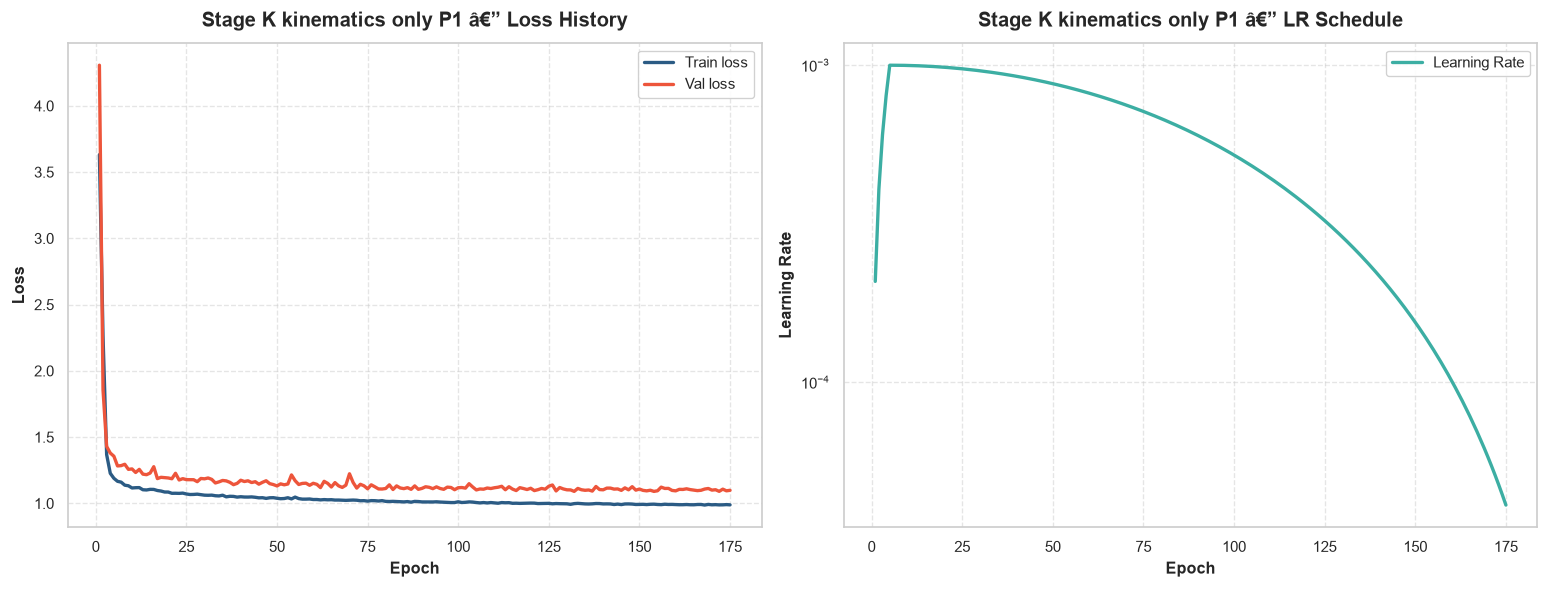

  [P1] Stage K complete in 35.5 min

  STAGE K (kinematics only)  P2
  Mean-predictor baseline loss (train): 3.5811
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P2
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 27.4 MB
  OK  VRAM reserved   : 514.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

...

  Ep  172 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep  172 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep  173 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep  173 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

Early stop at epoch 173 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.0328 (Epoch 153)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P2
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P2\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P2\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P2\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P2\best.pt  (best_val=1.0328)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P2\best.pt
  Stage K final train loss : 0.9776
  Stage K final val   loss : 1.0325
  Stage K best val loss    : 1.0328 (epoch 153)


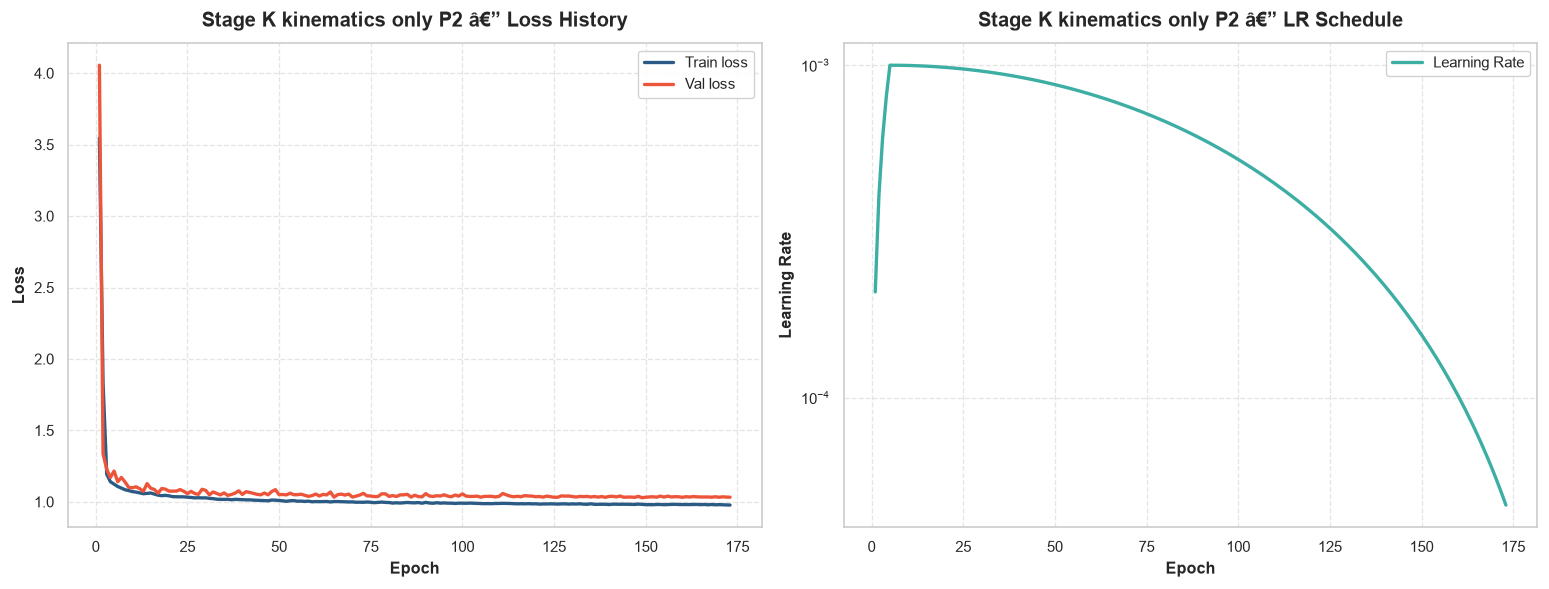

  [P2] Stage K complete in 43.2 min

  STAGE K (kinematics only)  P3
  Mean-predictor baseline loss (train): 3.4381
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P3
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 27.7 MB
  OK  VRAM reserved   : 516.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

...

  Ep  100 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep  100 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

  Ep  101 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep  101 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

Early stop at epoch 101 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.5978 (Epoch 81)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P3
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P3\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P3\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P3\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P3\best.pt  (best_val=1.5978)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P3\best.pt
  Stage K final train loss : 1.3488
  Stage K final val   loss : 1.6143
  Stage K best val loss    : 1.5978 (epoch 81)


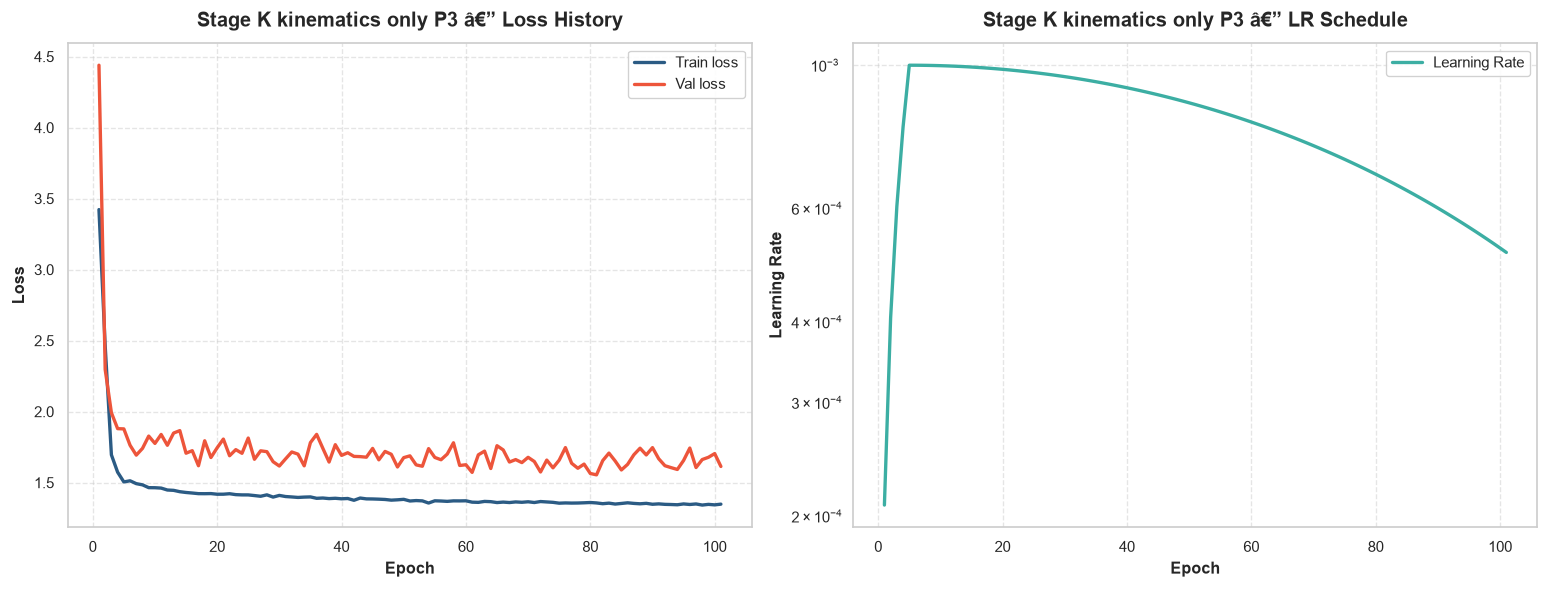

  [P3] Stage K complete in 19.0 min

  STAGE K (kinematics only)  P4
  Mean-predictor baseline loss (train): 3.5440
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P4
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 42.3 MB
  OK  VRAM reserved   : 516.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep  106 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep  106 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep  107 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep  107 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 107 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.0502 (Epoch 87)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P4
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P4\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P4\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P4\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P4\best.pt  (best_val=1.0502)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P4\best.pt
  Stage K final train loss : 1.0042
  Stage K final val   loss : 1.0510
  Stage K best val loss    : 1.0502 (epoch 87)


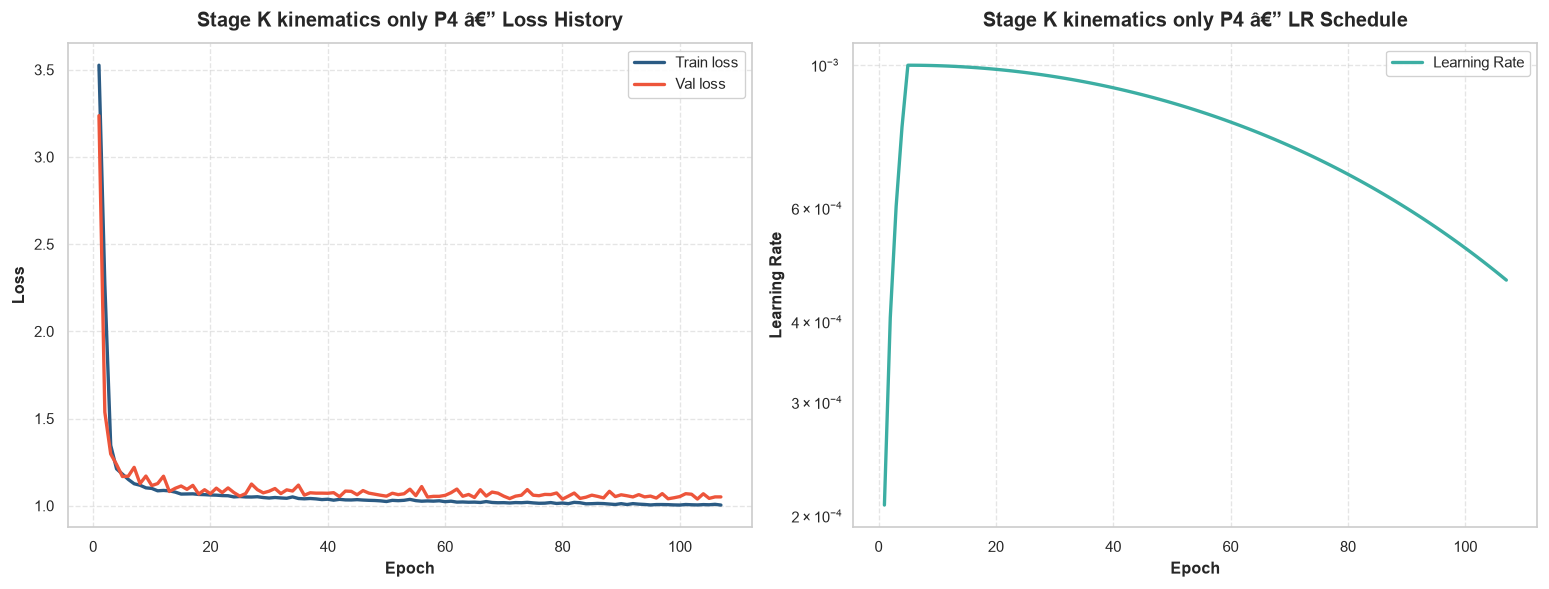

  [P4] Stage K complete in 21.5 min

  STAGE K (kinematics only)  P5
  Mean-predictor baseline loss (train): 3.3776
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P5
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 54.0 MB
  OK  VRAM reserved   : 518.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep  104 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep  104 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep  105 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep  105 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 105 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.7685 (Epoch 85)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P5
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P5\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P5\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P5\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P5\best.pt  (best_val=1.7685)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P5\best.pt
  Stage K final train loss : 1.5145
  Stage K final val   loss : 1.8067
  Stage K best val loss    : 1.7685 (epoch 85)


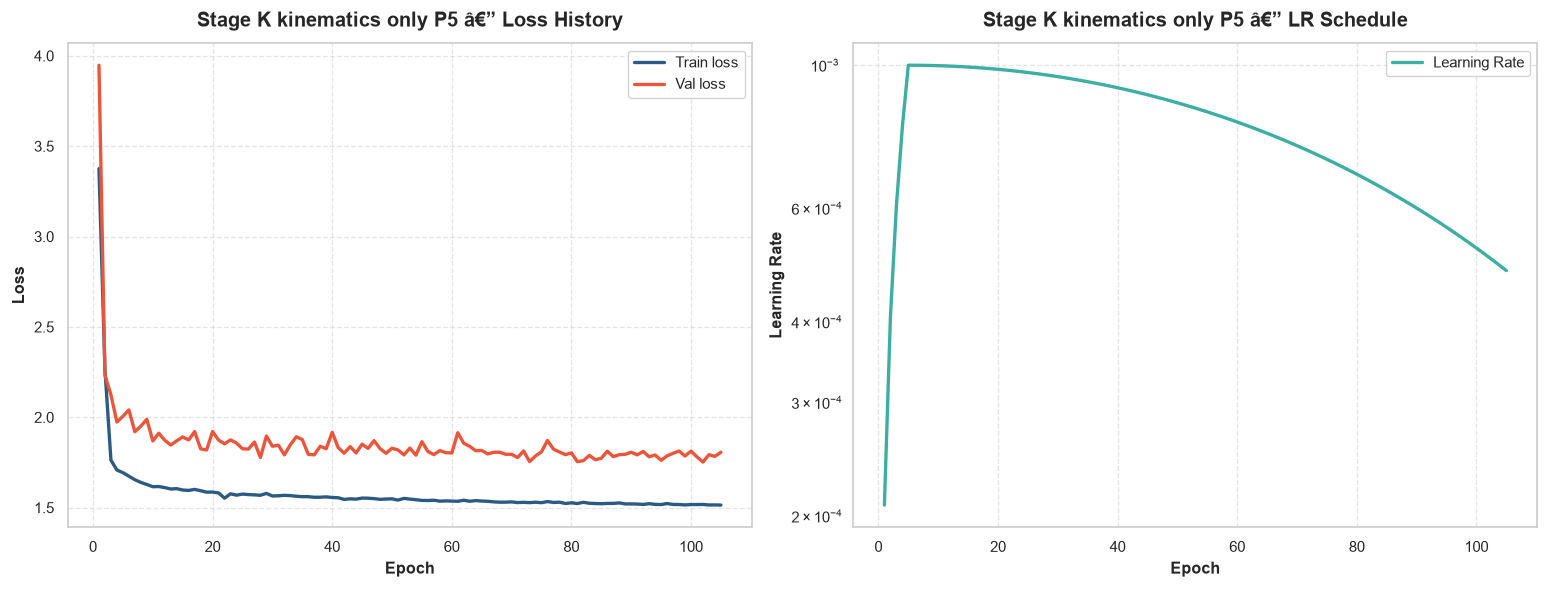

  [P5] Stage K complete in 22.7 min

  STAGE K (kinematics only)  P6
  Mean-predictor baseline loss (train): 3.5764
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P6
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 61.5 MB
  OK  VRAM reserved   : 562.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   47 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   47 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   48 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   48 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 48 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.3161 (Epoch 28)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P6
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P6\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P6\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P6\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P6\best.pt  (best_val=1.3161)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P6\best.pt
  Stage K final train loss : 1.2114
  Stage K final val   loss : 1.3133
  Stage K best val loss    : 1.3161 (epoch 28)


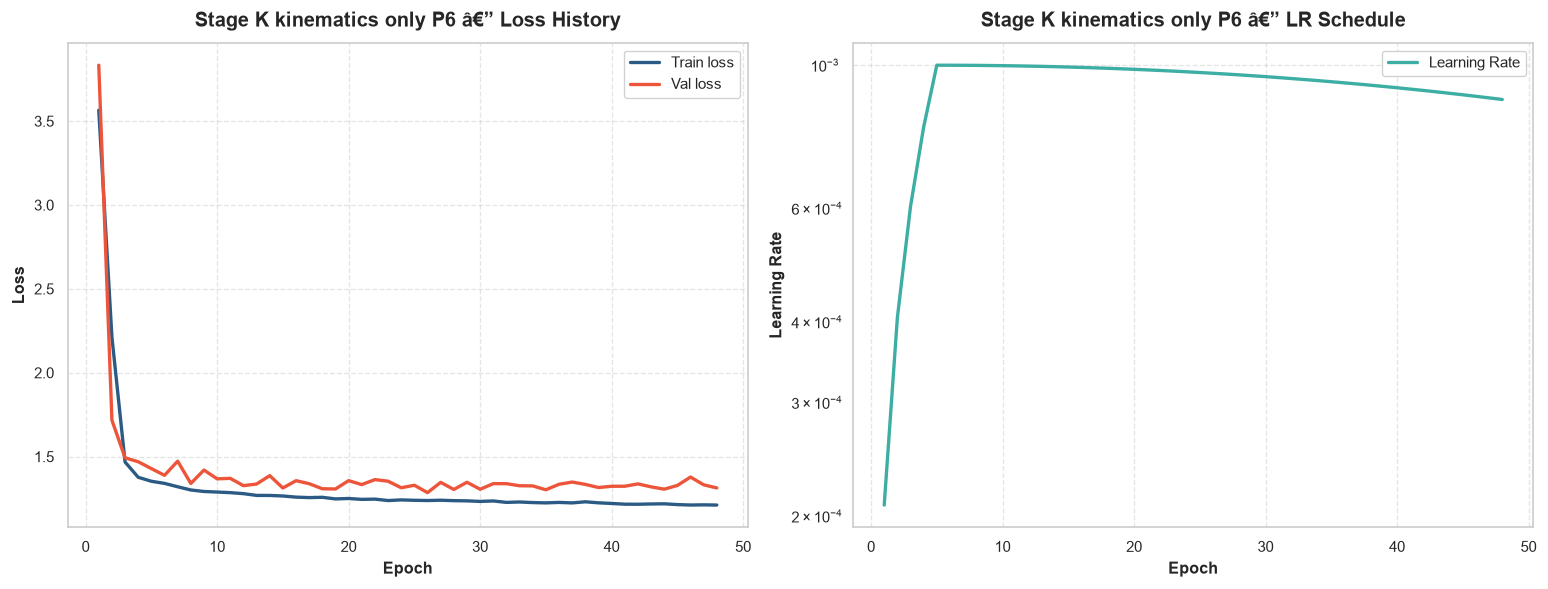

  [P6] Stage K complete in 10.5 min

  STAGE K (kinematics only)  P7
  Mean-predictor baseline loss (train): 3.5548
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P7
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 72.4 MB
  OK  VRAM reserved   : 566.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep  170 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep  170 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep  171 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep  171 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 171 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.2518 (Epoch 151)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P7
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P7\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P7\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P7\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P7\best.pt  (best_val=1.2518)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P7\best.pt
  Stage K final train loss : 1.0417
  Stage K final val   loss : 1.2569
  Stage K best val loss    : 1.2518 (epoch 151)


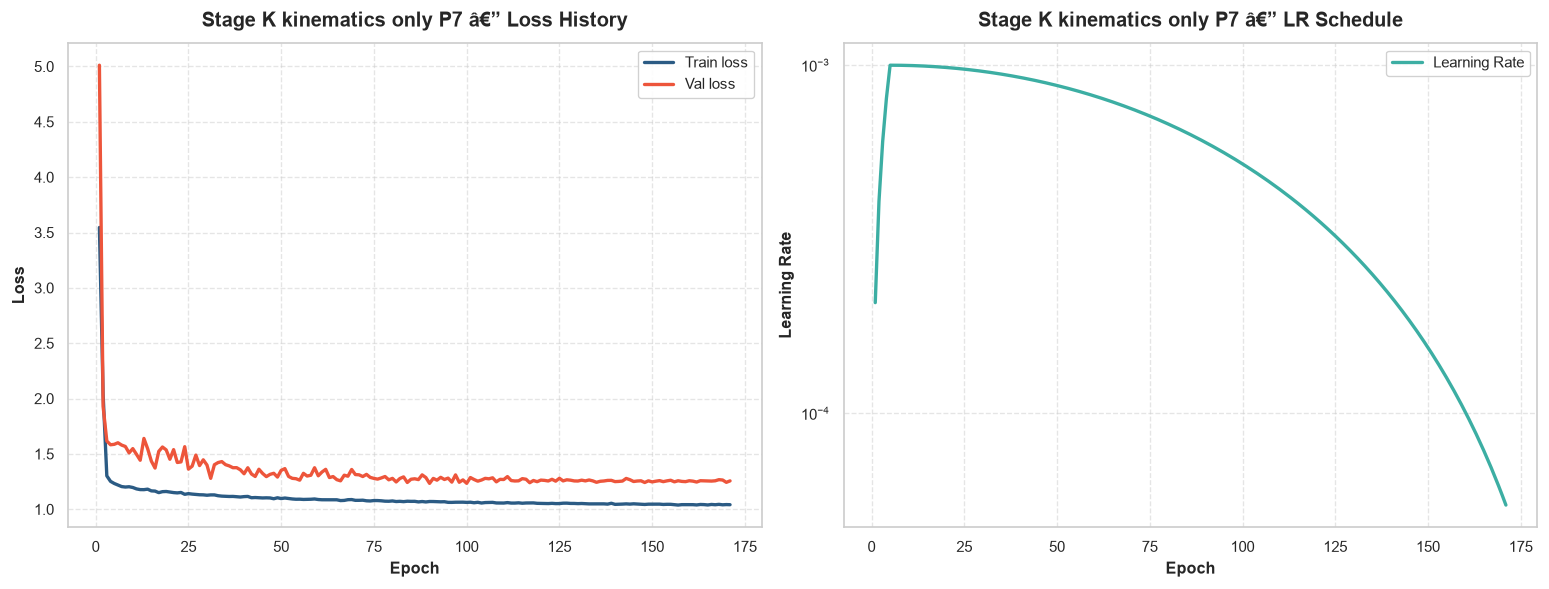

  [P7] Stage K complete in 40.9 min

  STAGE K (kinematics only)  P8
  Mean-predictor baseline loss (train): 3.4285
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P8
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 70.4 MB
  OK  VRAM reserved   : 568.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep  124 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep  124 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep  125 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep  125 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 125 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.6555 (Epoch 105)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P8
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P8\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P8\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P8\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P8\best.pt  (best_val=1.6555)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P8\best.pt
  Stage K final train loss : 1.4731
  Stage K final val   loss : 1.6653
  Stage K best val loss    : 1.6555 (epoch 105)


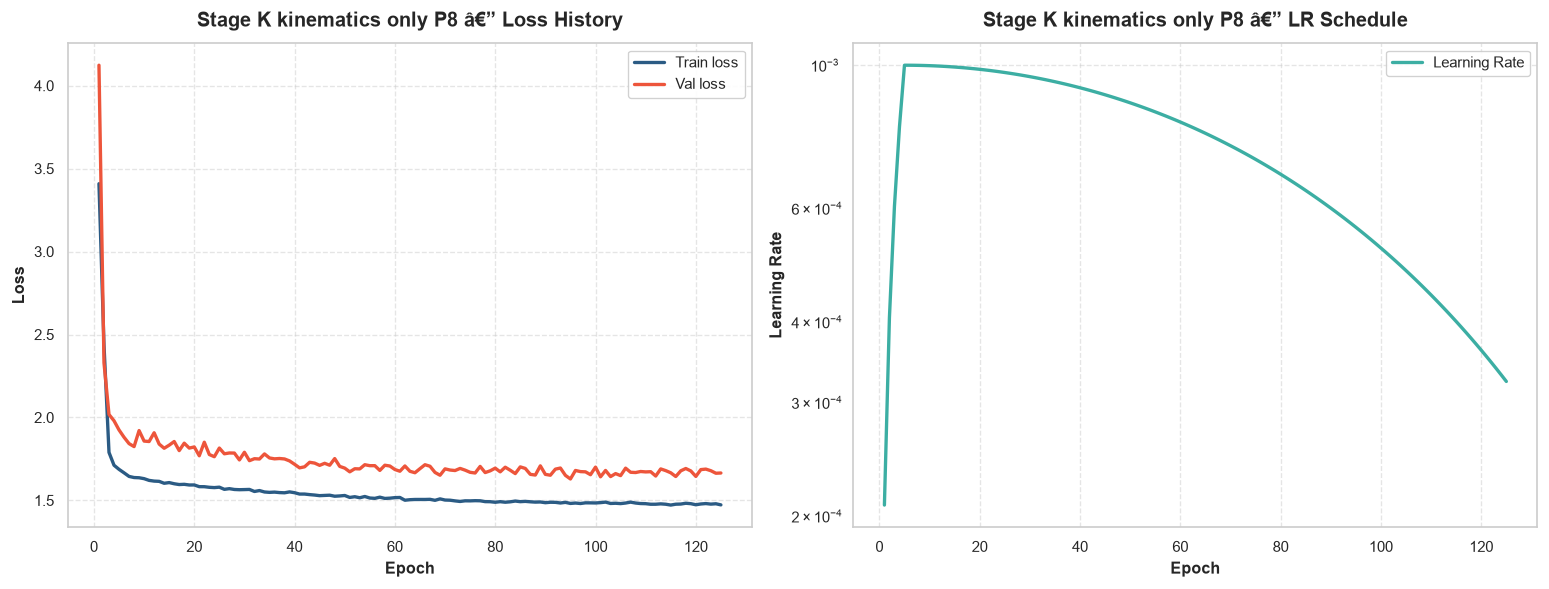

  [P8] Stage K complete in 24.3 min

  STAGE K (kinematics only)  P9
  Mean-predictor baseline loss (train): 3.5772
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P9
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 83.0 MB
  OK  VRAM reserved   : 568.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run

  Ep    1 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   81 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   81 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   82 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   82 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 82 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.8644 (Epoch 62)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P9
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P9\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P9\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P9\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P9\best.pt  (best_val=0.8644)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P9\best.pt
  Stage K final train loss : 0.9459
  Stage K final val   loss : 0.8621
  Stage K best val loss    : 0.8644 (epoch 62)


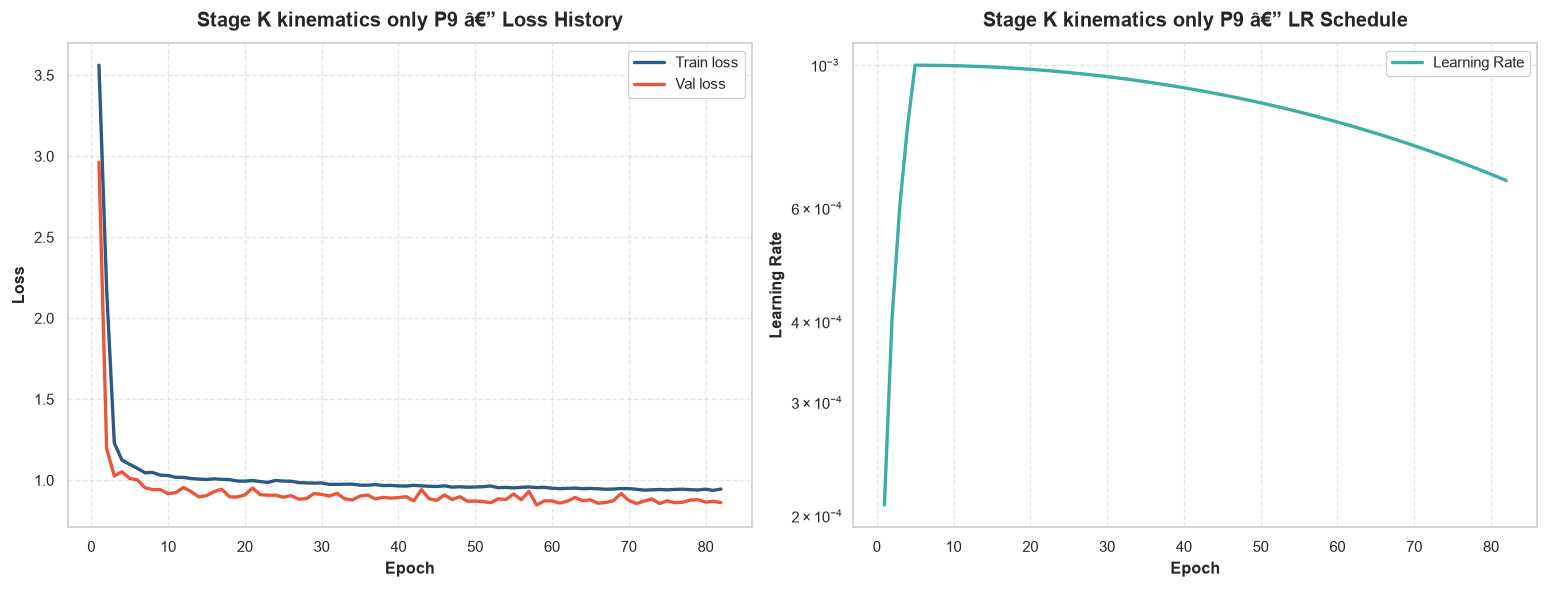

  [P9] Stage K complete in 16.9 min

  STAGE K (kinematics only)  P10
  Mean-predictor baseline loss (train): 3.5541
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P10
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 97.4 MB
  OK  VRAM reserved   : 568.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training r

  Ep    1 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   80 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   80 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   81 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   81 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 81 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.4086 (Epoch 61)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P10
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P10\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P10\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P10\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P10\best.pt  (best_val=1.4086)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P10\best.pt
  Stage K final train loss : 1.0991
  Stage K final val   loss : 1.4207
  Stage K best val loss    : 1.4086 (epoch 61)


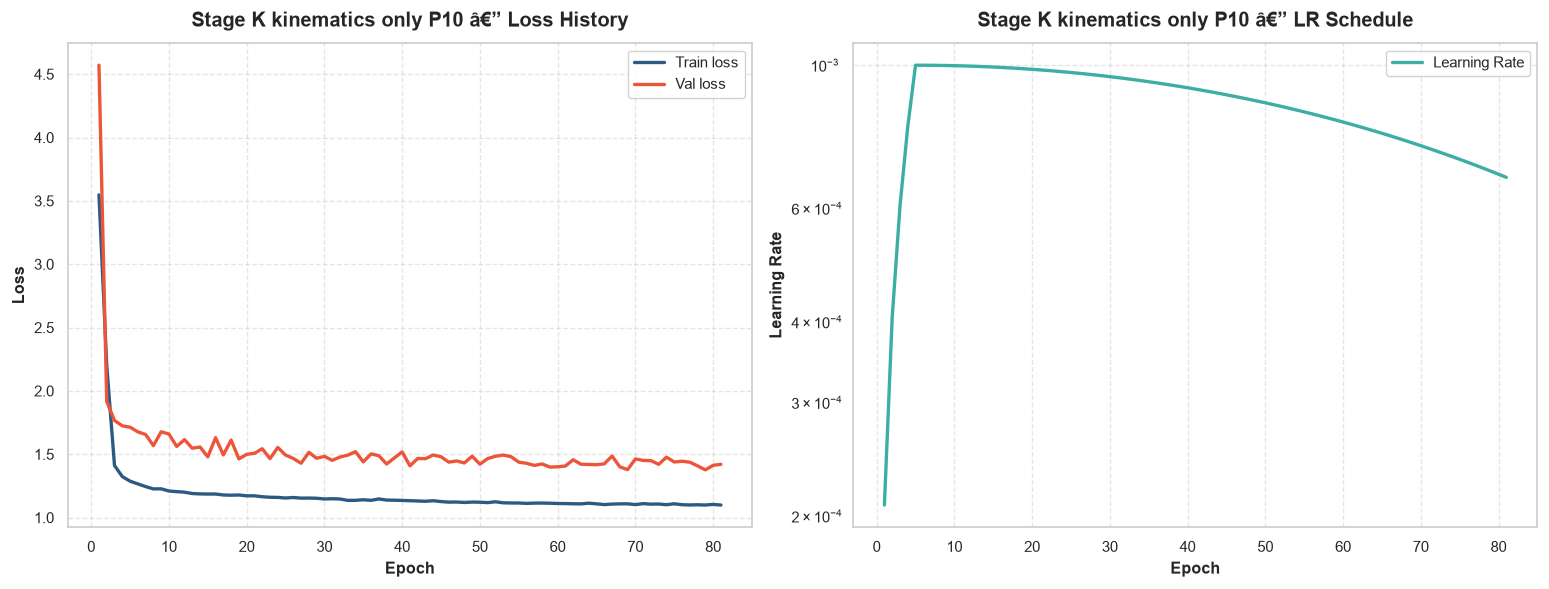

  [P10] Stage K complete in 17.2 min

  STAGE K (kinematics only)  P11
  Mean-predictor baseline loss (train): 3.4739
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P11
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 112.1 MB
  OK  VRAM reserved   : 568.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   98 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   98 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   99 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   99 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 99 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.1021 (Epoch 79)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P11
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P11\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P11\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P11\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P11\best.pt  (best_val=1.1021)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P11\best.pt
  Stage K final train loss : 1.1025
  Stage K final val   loss : 1.1012
  Stage K best val loss    : 1.1021 (epoch 79)


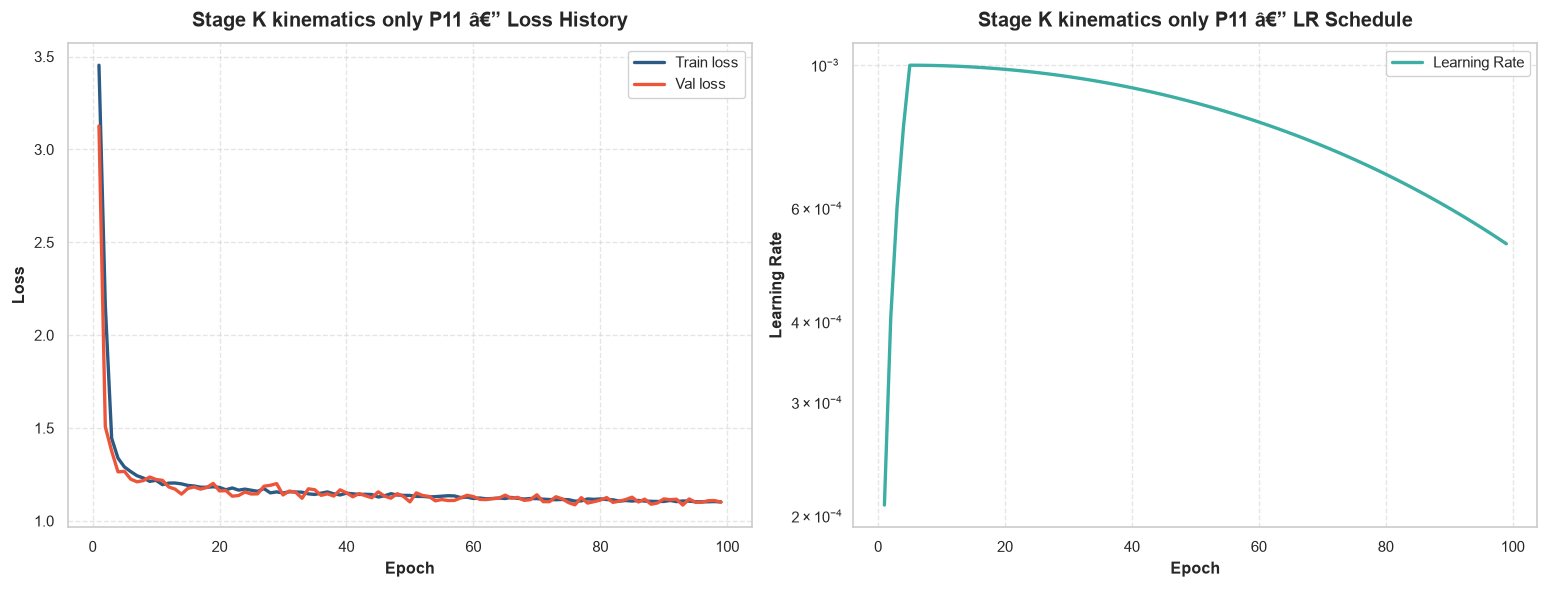

  [P11] Stage K complete in 21.3 min

  STAGE K (kinematics only)  P12
  Mean-predictor baseline loss (train): 3.4934
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/kin_only/P12
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 123.9 MB
  OK  VRAM reserved   : 612.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training

  Ep    1 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

...

  Ep   62 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   62 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep   63 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   63 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

Early stop at epoch 63 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.3238 (Epoch 43)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\kin_only\P12
Metrics & Report saved: outputs\checkpoints_residual_p2c\kin_only\P12\metrics.json | outputs\checkpoints_residual_p2c\kin_only\P12\metrics.csv | outputs\checkpoints_residual_p2c\kin_only\P12\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\kin_only\P12\best.pt  (best_val=1.3238)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\kin_only\P12\best.pt
  Stage K final train loss : 1.2271
  Stage K final val   loss : 1.3291
  Stage K best val loss    : 1.3238 (epoch 43)


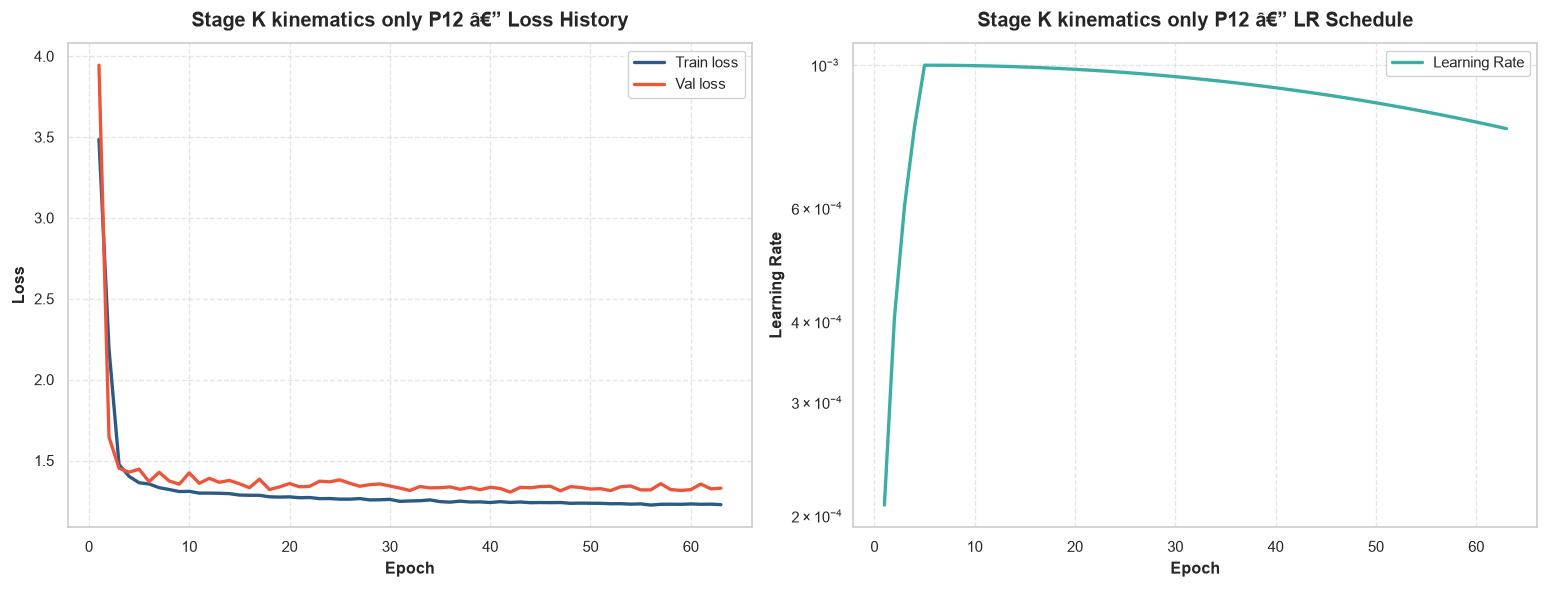

  [P12] Stage K complete in 14.4 min

✓  Stage K done for ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12']


In [7]:
# ============================================================================
# STAGE K — KINEMATICS-ONLY MODEL  (per subject)
# ============================================================================
# Same KG-GT architecture, called with use_eeg=False (KinOnly wrapper): the encoder is not
# run, its output is replaced by zeros, the node embeddings are the node-projection bias.
# Loss: the composite loss of CONFIG with the EEG-specific parts off
#   training.loss.w_eeg_only = 0, model.kin_dropout = 0, model.eeg_only_aux = False
# (they only exist to make the EEG path contribute). Everything else is CONFIG.
# Checkpoints: <training.checkpoint_dir>/kin_only/{subject}/ ; the best one is loaded
# and kept in stage_k[subject]["model"] for Stage E and the evaluation.
# ─────────────────────────────────────────────────────────────────────────────
import time

_res_cfg = notebook_cfg["residual"]
stage_k = {}   # keyed by "P{id}"

for _subj, _sd in subject_data.items():
    _t_fold = time.time()
    print(f"\n{'='*70}")
    print(f"  STAGE K (kinematics only)  {_subj}")
    print(f"{'='*70}")

    _cfg_k = copy.deepcopy(_sd["cfg"])
    _cfg_k["model"]["kin_dropout"] = 0.0
    _cfg_k["model"]["eeg_only_aux"] = False
    _cfg_k["training"]["loss"]["w_eeg_only"] = 0.0
    _loss_k = build_loss_from_config(_cfg_k["training"], channel_weights=_sd["channel_weights"])

    torch.manual_seed(_res_cfg["seed"])
    _kin_model = KinOnly(build_kg_gt_from_config(
        _cfg_k, input_dim=_sd["true_eeg_dim"], kin_dim=_sd["true_kin_dim"], edge_prior=_sd["edge_prior"],
    )).to(device)

    _baseline = compute_mean_baseline_loss(
        _sd["train_loader"], loss_fn=_loss_k, device=device, prepare_batch=_sd["prepare_batch"]
    )
    print(f"  Mean-predictor baseline loss (train): {_baseline:.4f}")

    _kin_best, _r, _ckpt_dir = train_stage(
        _cfg_k, "kin_only", _subj, _kin_model,
        _sd["train_loader"], _sd["val_loader"], _sd["prepare_batch"], _loss_k,
        max_epochs=_res_cfg["kin_epochs"], device=device,
    )
    if _r.history["train"]:
        print(f"  Stage K final train loss : {_r.history['train'][-1]:.4f}")
        print(f"  Stage K final val   loss : {_r.history['val'][-1]:.4f}")
    print(f"  Stage K best val loss    : {_r.best_val:.4f} (epoch {_r.best_epoch})")
    _fig_hist = plot_training_history(_r.history, stage=f"Stage K kinematics only {_subj}", cfg=_cfg_k)
    plt.show()

    stage_k[_subj] = dict(model=_kin_best, result=_r, cfg=_cfg_k, checkpoint_dir=_ckpt_dir)
    del _kin_model
    print(f"  [{_subj}] Stage K complete in {(time.time() - _t_fold) / 60.0:.1f} min")

print(f"\n✓  Stage K done for {list(stage_k.keys())}")


### Stage E — EEG model on the residual

The Stage-K model is frozen. Target of every batch: `emg_z − kin_pred_z`. `EEGOnly(model)` calls a new KG-GT model with `use_kin=False` (no kinematic edge bias, no kin skip). The printed "zero residual" loss is the value of predicting 0 everywhere, i.e. of adding nothing to the kinematics-only model.



  STAGE E (EEG on the residual)  P1
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2764 | val 0.3159   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P1
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 111.8 MB
  OK  VRAM reserved   : 1016.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : 

  Ep    1 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

[SDPA] SDPA backend active: flash_attention  (flash=True, mem_efficient=True). For best performance with T=4000, ensure AMP (fp16) is enabled and PyTorch >= 2.0 is installed.


  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

...

  Ep   92 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep   92 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   93 [train]:   0%|          | 0/68 [00:00<?, ?batch/s]

  Ep   93 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 93 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2971 (Epoch 73)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P1
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P1\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P1\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P1\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P1\best.pt  (best_val=0.2971)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P1\best.pt
  Stage E final train loss : 0.2001
  Stage E final val   loss : 0.2976
  Stage E best val loss    : 0.2971 (epoch 73; smoothed over 5 epochs)   zero-residual val loss 0.3159   difference -0.0188 (negative = below the baseline)


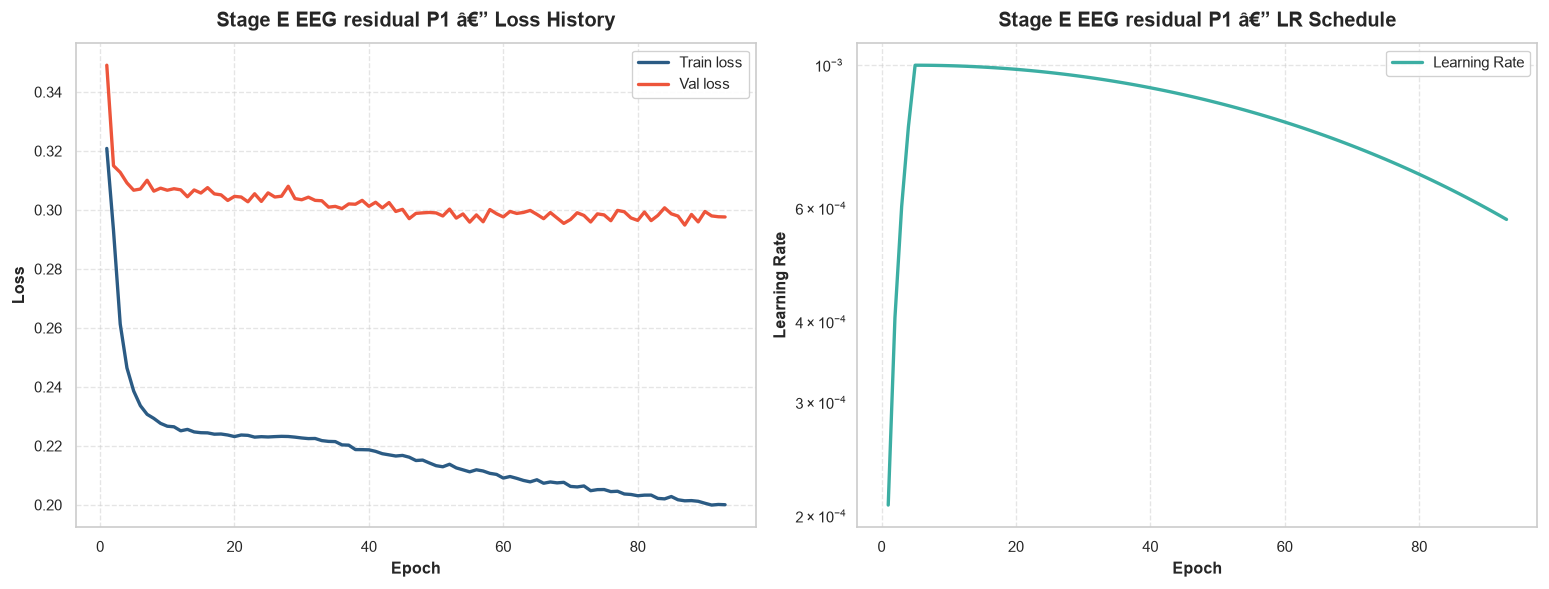

  [P1] Stage E complete in 26.3 min

  STAGE E (EEG on the residual)  P2
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2775 | val 0.2988   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P2
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 148.0 MB
  OK  VRAM reserved   : 1300.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

...

  Ep   63 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep   63 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep   64 [train]:   0%|          | 0/84 [00:00<?, ?batch/s]

  Ep   64 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

Early stop at epoch 64 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2758 (Epoch 44)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P2
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P2\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P2\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P2\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P2\best.pt  (best_val=0.2758)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P2\best.pt
  Stage E final train loss : 0.2179
  Stage E final val   loss : 0.2764
  Stage E best val loss    : 0.2758 (epoch 44; smoothed over 5 epochs)   zero-residual val loss 0.2988   difference -0.0229 (negative = below the baseline)


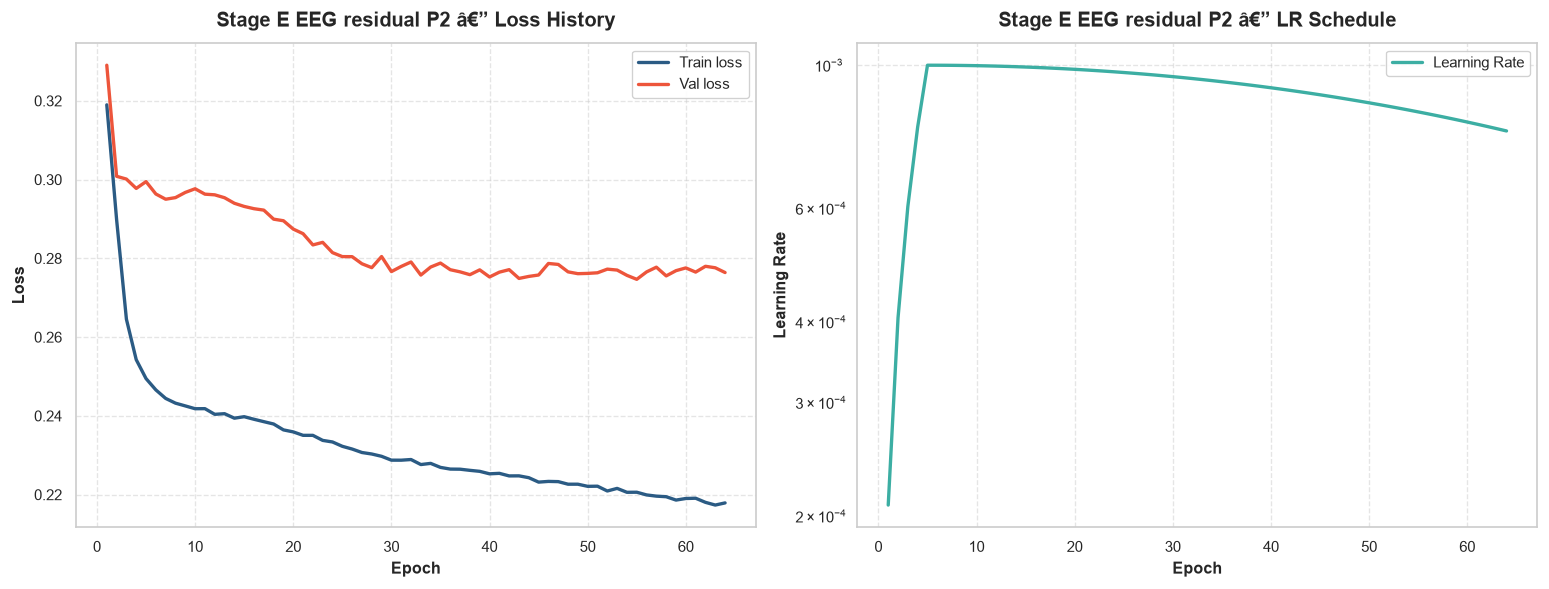

  [P2] Stage E complete in 22.5 min

  STAGE E (EEG on the residual)  P3
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.3289 | val 0.3578   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P3
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 183.3 MB
  OK  VRAM reserved   : 1300.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

...

  Ep   23 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep   23 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

  Ep   24 [train]:   0%|          | 0/63 [00:00<?, ?batch/s]

  Ep   24 [val  ]:   0%|          | 0/7 [00:00<?, ?batch/s]

Early stop at epoch 24 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3657 (Epoch 4)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P3
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P3\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P3\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P3\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P3\best.pt  (best_val=0.3657)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P3\best.pt
  Stage E final train loss : 0.2836
  Stage E final val   loss : 0.3667
  Stage E best val loss    : 0.3657 (epoch 4; smoothed over 5 epochs)   zero-residual val loss 0.3578   difference +0.0080 (negative = below the baseline)


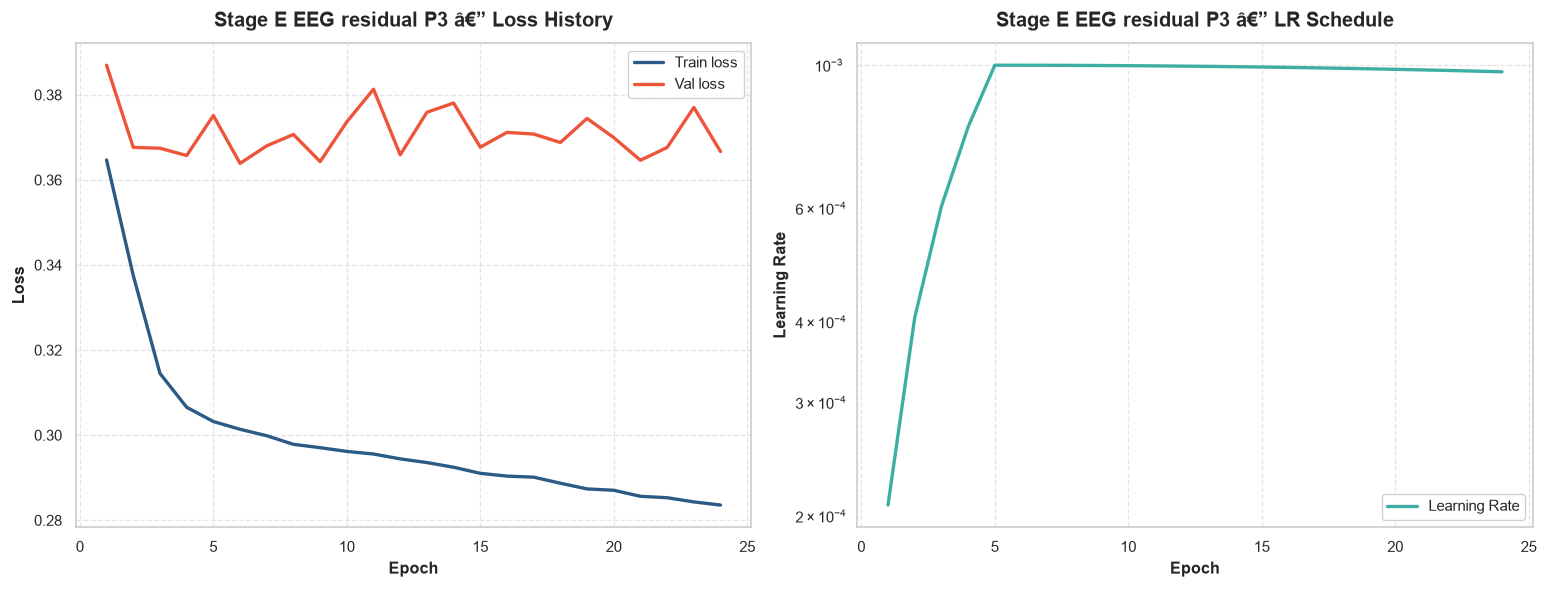

  [P3] Stage E complete in 6.4 min

  STAGE E (EEG on the residual)  P4
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2734 | val 0.2935   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P4
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 320.6 MB
  OK  VRAM reserved   : 1300.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing

  Ep    1 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   53 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep   53 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   54 [train]:   0%|          | 0/67 [00:00<?, ?batch/s]

  Ep   54 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 54 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2706 (Epoch 34)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P4
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P4\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P4\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P4\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P4\best.pt  (best_val=0.2706)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P4\best.pt
  Stage E final train loss : 0.2098
  Stage E final val   loss : 0.2709
  Stage E best val loss    : 0.2706 (epoch 34; smoothed over 5 epochs)   zero-residual val loss 0.2935   difference -0.0228 (negative = below the baseline)


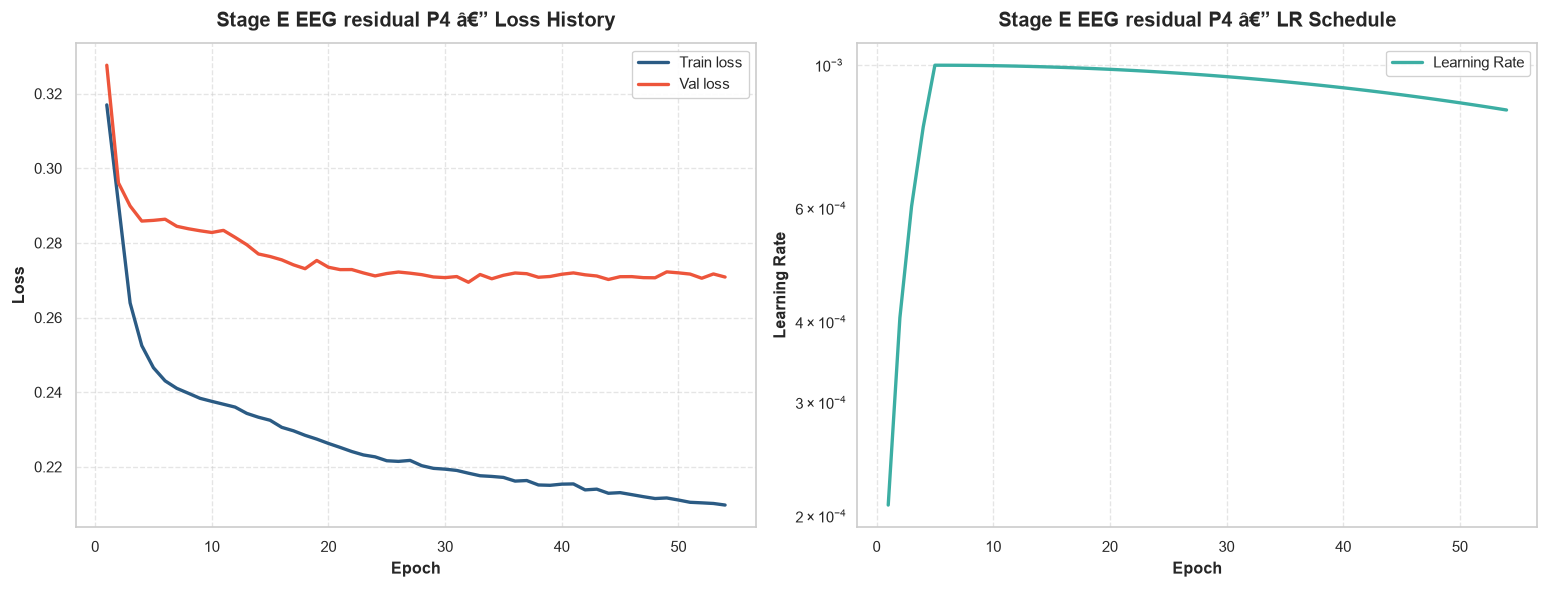

  [P4] Stage E complete in 15.2 min

  STAGE E (EEG on the residual)  P5
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.3436 | val 0.3830   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P5
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 405.1 MB
  OK  VRAM reserved   : 1542.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   56 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   56 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   57 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   57 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 57 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3659 (Epoch 37)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P5
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P5\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P5\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P5\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P5\best.pt  (best_val=0.3659)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P5\best.pt
  Stage E final train loss : 0.2797
  Stage E final val   loss : 0.3704
  Stage E best val loss    : 0.3659 (epoch 37; smoothed over 5 epochs)   zero-residual val loss 0.3830   difference -0.0171 (negative = below the baseline)


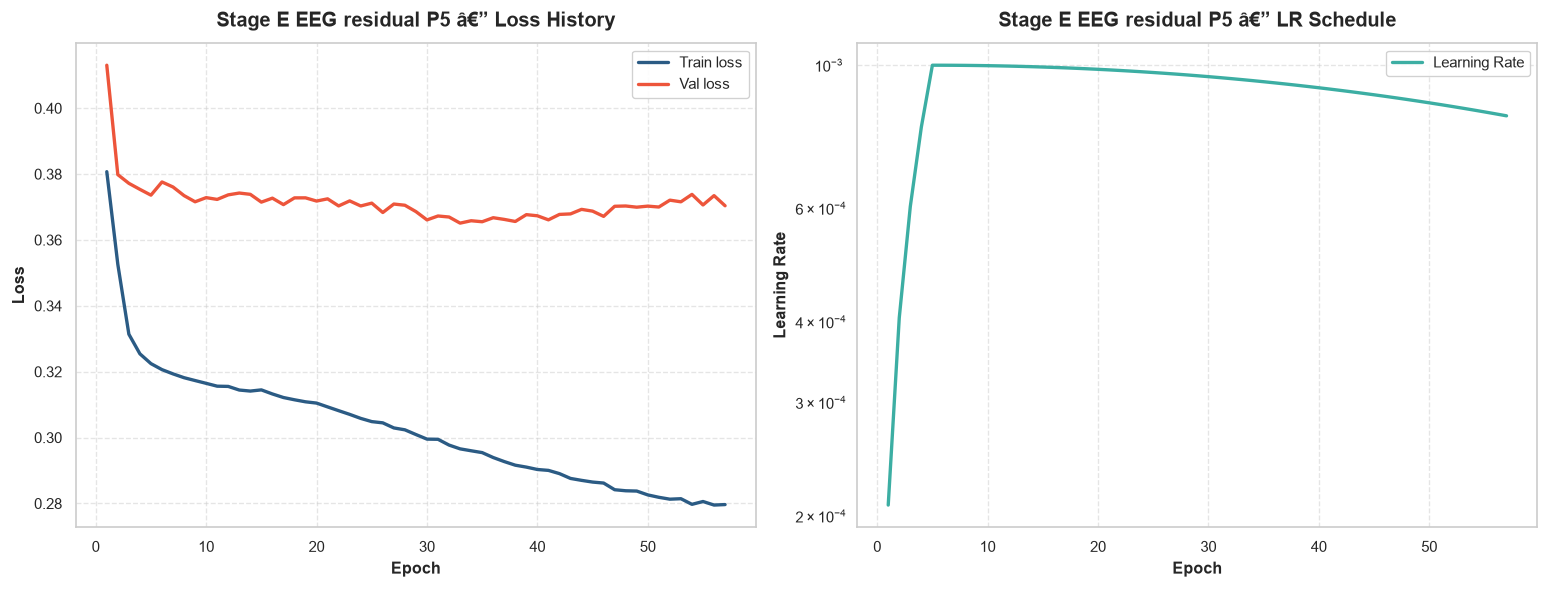

  [P5] Stage E complete in 17.3 min

  STAGE E (EEG on the residual)  P6
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.3204 | val 0.3281   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P6
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 442.2 MB
  OK  VRAM reserved   : 1544.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   40 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   40 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   41 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   41 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 41 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3269 (Epoch 21)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P6
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P6\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P6\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P6\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P6\best.pt  (best_val=0.3269)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P6\best.pt
  Stage E final train loss : 0.2625
  Stage E final val   loss : 0.3365
  Stage E best val loss    : 0.3269 (epoch 21; smoothed over 5 epochs)   zero-residual val loss 0.3281   difference -0.0012 (negative = below the baseline)


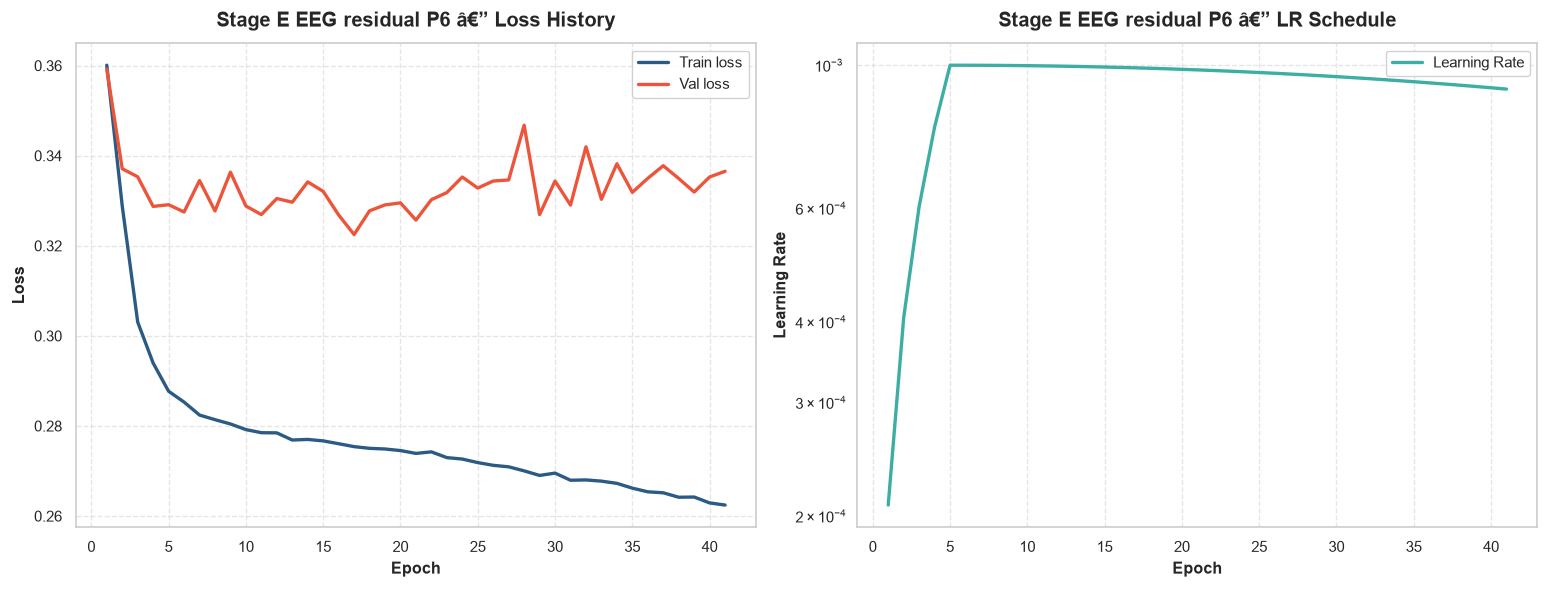

  [P6] Stage E complete in 12.5 min

  STAGE E (EEG on the residual)  P7
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2879 | val 0.3194   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P7
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 522.4 MB
  OK  VRAM reserved   : 1548.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   53 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep   53 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   54 [train]:   0%|          | 0/80 [00:00<?, ?batch/s]

  Ep   54 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 54 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2920 (Epoch 34)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P7
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P7\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P7\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P7\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P7\best.pt  (best_val=0.2920)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P7\best.pt
  Stage E final train loss : 0.2266
  Stage E final val   loss : 0.2947
  Stage E best val loss    : 0.2920 (epoch 34; smoothed over 5 epochs)   zero-residual val loss 0.3194   difference -0.0274 (negative = below the baseline)


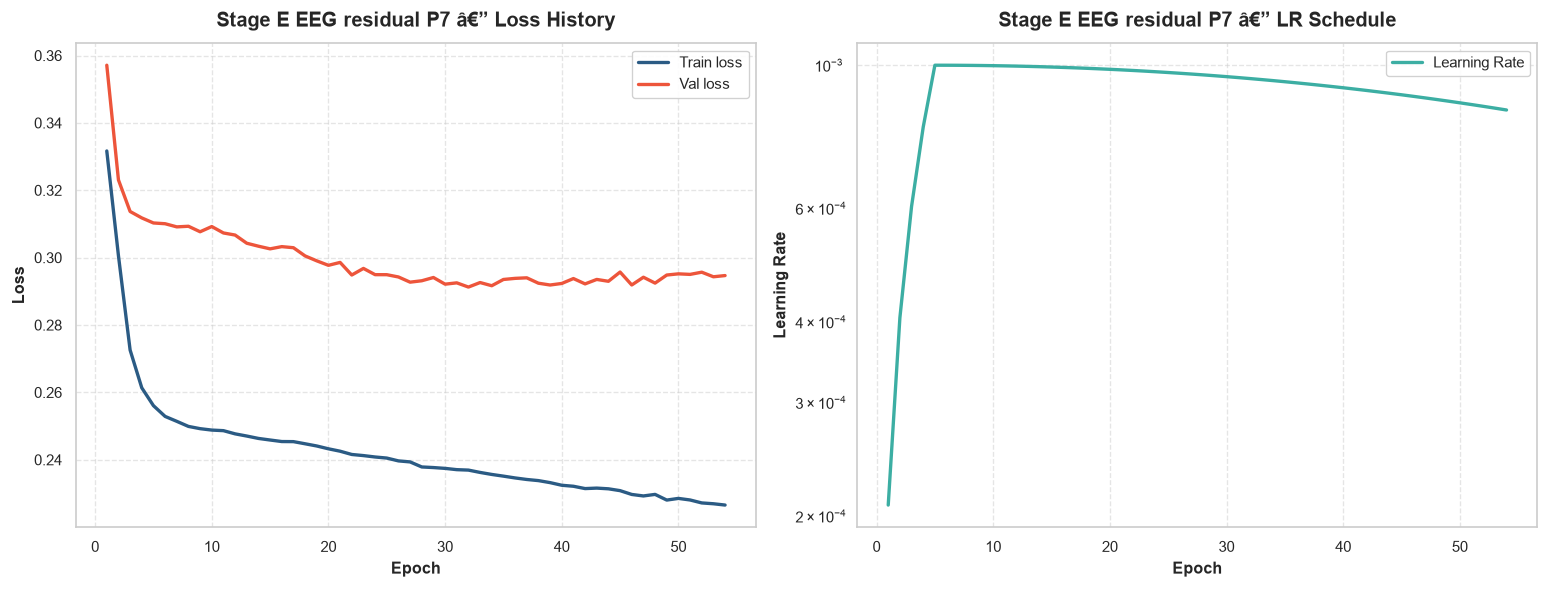

  [P7] Stage E complete in 18.1 min

  STAGE E (EEG on the residual)  P8
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.3334 | val 0.3636   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P8
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 615.9 MB
  OK  VRAM reserved   : 1550.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   52 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   52 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   53 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   53 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 53 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3400 (Epoch 33)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P8
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P8\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P8\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P8\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P8\best.pt  (best_val=0.3400)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P8\best.pt
  Stage E final train loss : 0.2693
  Stage E final val   loss : 0.3466
  Stage E best val loss    : 0.3400 (epoch 33; smoothed over 5 epochs)   zero-residual val loss 0.3636   difference -0.0236 (negative = below the baseline)


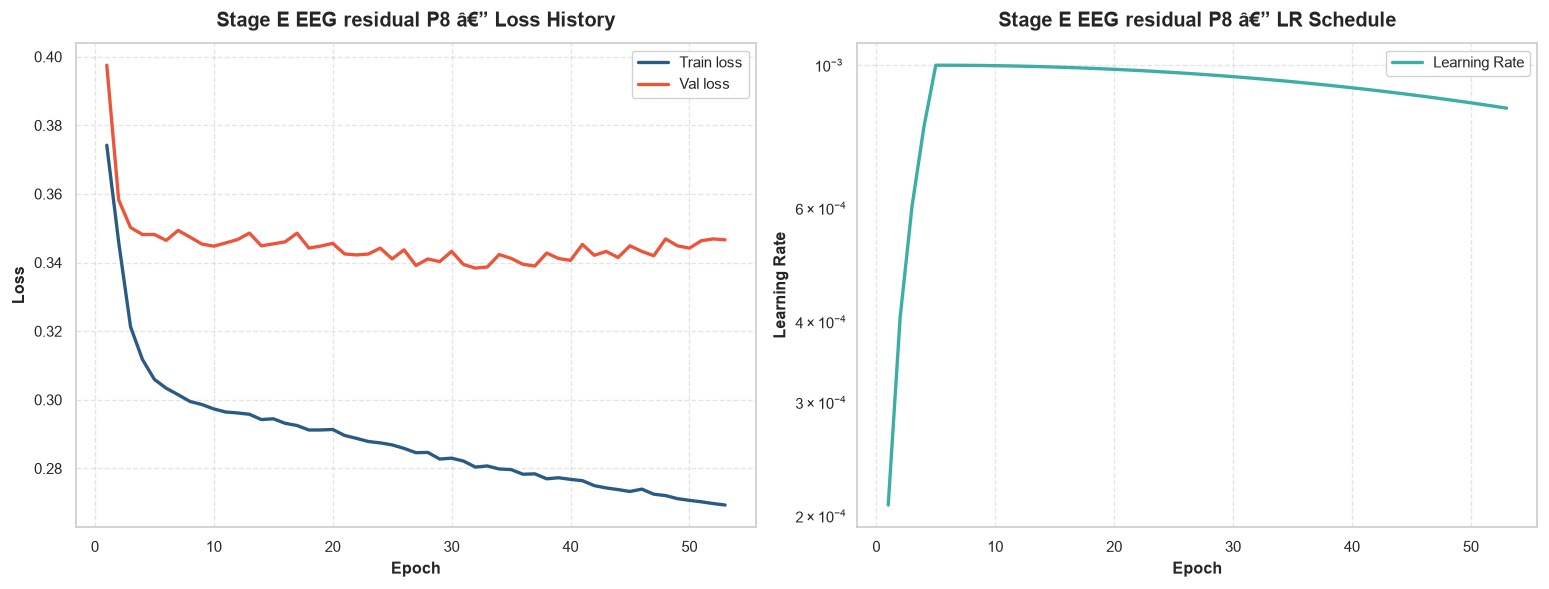

  [P8] Stage E complete in 14.5 min

  STAGE E (EEG on the residual)  P9
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2743 | val 0.2804   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P9
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 690.0 MB
  OK  VRAM reserved   : 1554.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turin

  Ep    1 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   73 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   73 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   74 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   74 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 74 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2657 (Epoch 54)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P9
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P9\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P9\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P9\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P9\best.pt  (best_val=0.2657)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P9\best.pt
  Stage E final train loss : 0.2151
  Stage E final val   loss : 0.2682
  Stage E best val loss    : 0.2657 (epoch 54; smoothed over 5 epochs)   zero-residual val loss 0.2804   difference -0.0147 (negative = below the baseline)


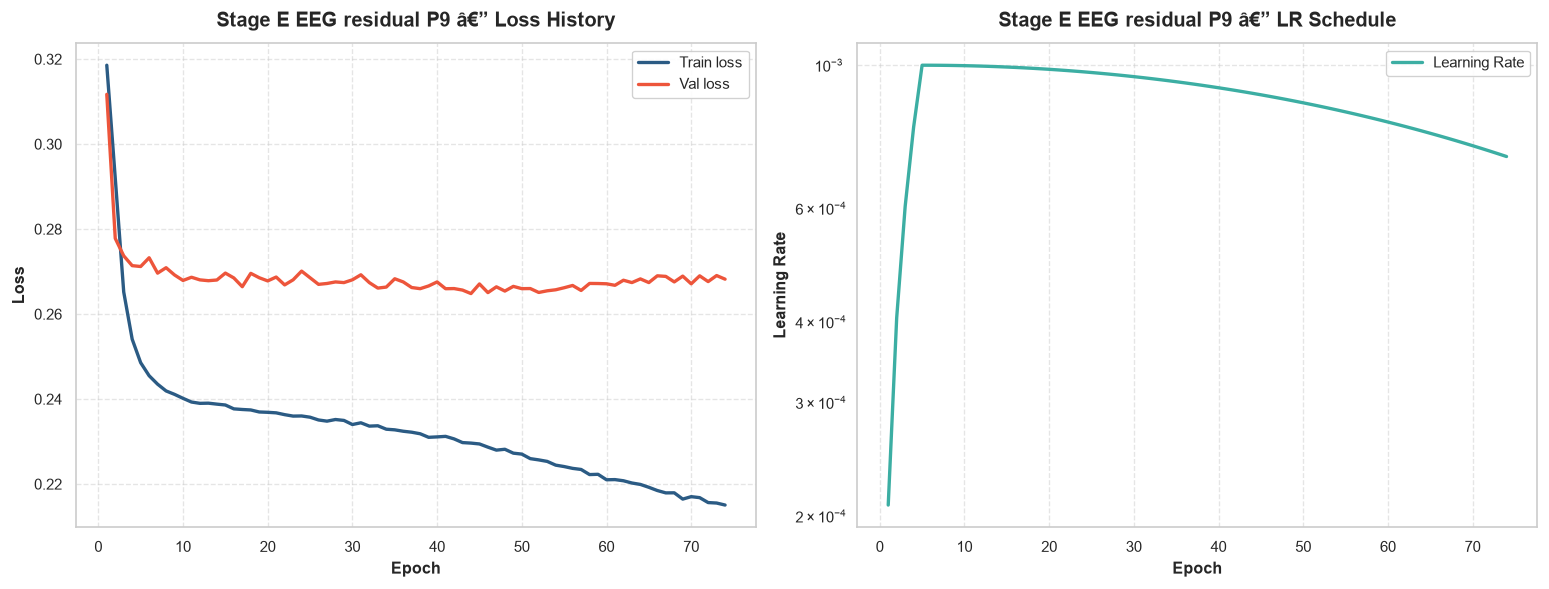

  [P9] Stage E complete in 21.4 min

  STAGE E (EEG on the residual)  P10
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2897 | val 0.3265   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P10
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 812.5 MB
  OK  VRAM reserved   : 1714.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Tur

  Ep    1 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   40 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   40 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   41 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   41 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 41 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3210 (Epoch 21)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P10
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P10\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P10\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P10\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P10\best.pt  (best_val=0.3210)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P10\best.pt
  Stage E final train loss : 0.2293
  Stage E final val   loss : 0.3341
  Stage E best val loss    : 0.3210 (epoch 21; smoothed over 5 epochs)   zero-residual val loss 0.3265   difference -0.0055 (negative = below the baseline)


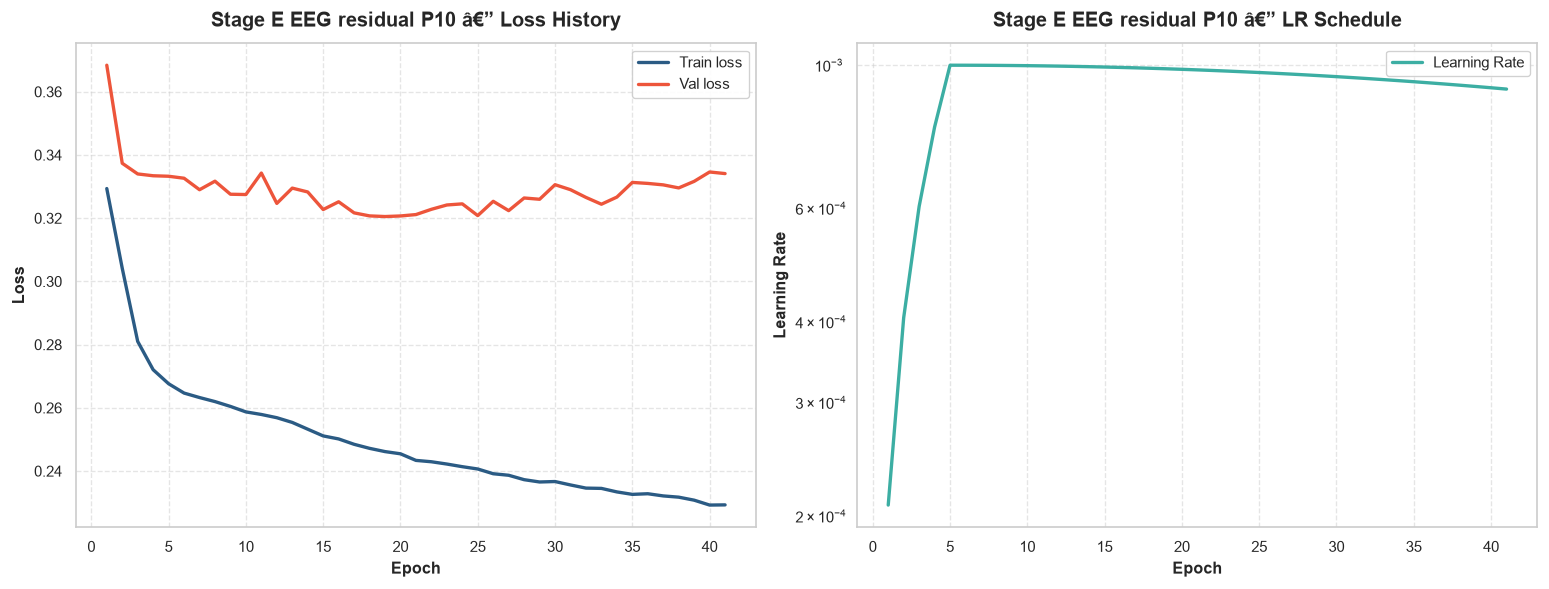

  [P10] Stage E complete in 12.3 min

  STAGE E (EEG on the residual)  P11
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.2896 | val 0.3064   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P11
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 955.2 MB
  OK  VRAM reserved   : 1874.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Tu

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   56 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   56 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   57 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   57 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 57 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.2959 (Epoch 37)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P11
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P11\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P11\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P11\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P11\best.pt  (best_val=0.2959)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P11\best.pt
  Stage E final train loss : 0.2340
  Stage E final val   loss : 0.3007
  Stage E best val loss    : 0.2959 (epoch 37; smoothed over 5 epochs)   zero-residual val loss 0.3064   difference -0.0105 (negative = below the baseline)


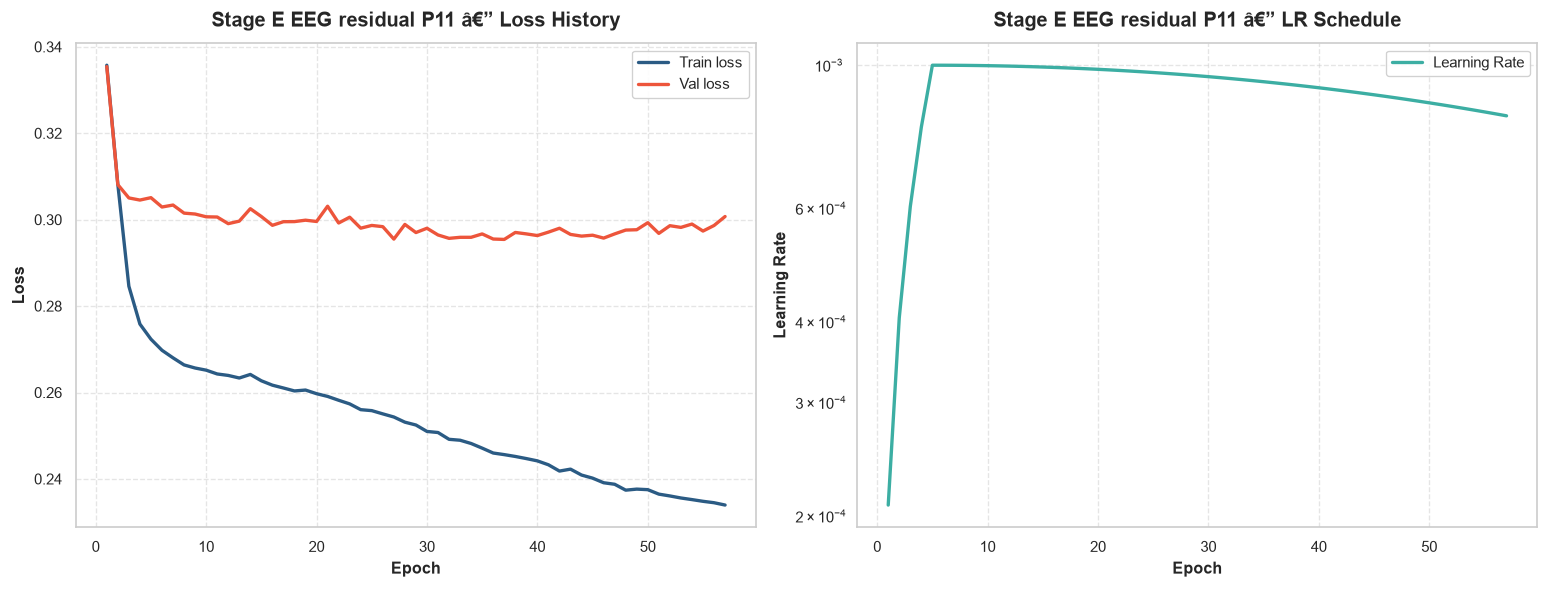

  [P11] Stage E complete in 17.3 min

  STAGE E (EEG on the residual)  P12
  EEG input dim 128 | electrode dropout 0.2 (x4 columns) | encoder dropout 0.3
  Zero-residual baseline loss: train 0.3083 | val 0.3413   (a model that adds nothing to Stage K)
  Parameters           : 240,931 (a wrapped model only updates the paths it uses)
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs/checkpoints_residual_p2c/eeg_residual/P12
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 1033.1 MB
  OK  VRAM reserved   : 2034.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- T

  Ep    1 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

...

  Ep   37 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   37 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep   38 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   38 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

Early stop at epoch 38 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.3198 (Epoch 18)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_residual_p2c\eeg_residual\P12
Metrics & Report saved: outputs\checkpoints_residual_p2c\eeg_residual\P12\metrics.json | outputs\checkpoints_residual_p2c\eeg_residual\P12\metrics.csv | outputs\checkpoints_residual_p2c\eeg_residual\P12\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_residual_p2c\eeg_residual\P12\best.pt  (best_val=0.3198)
  Loaded best checkpoint: outputs\checkpoints_residual_p2c\eeg_residual\P12\best.pt
  Stage E final train loss : 0.2587
  Stage E final val   loss : 0.3274
  Stage E best val loss    : 0.3198 (epoch 18; smoothed over 5 epochs)   zero-residual val loss 0.3413   difference -0.0215 (negative = below the baseline)


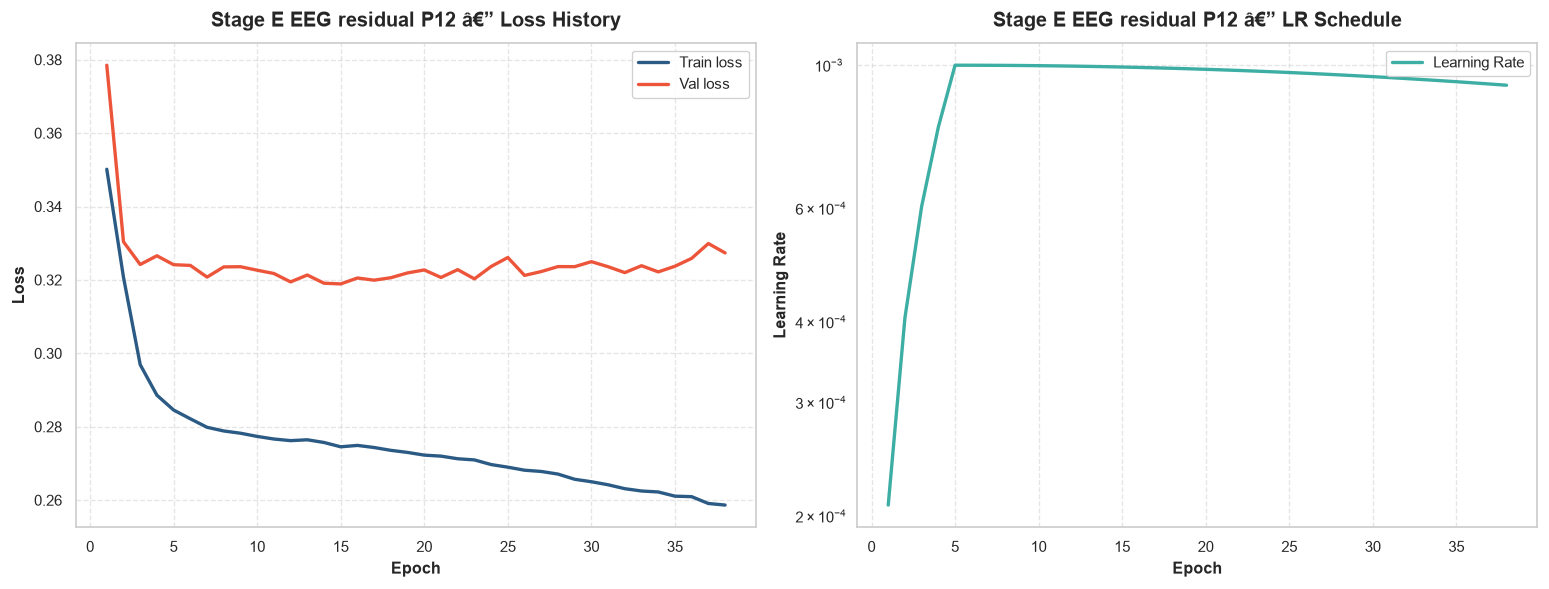

  [P12] Stage E complete in 12.2 min

✓  Stage E done for ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12']


In [8]:
# ============================================================================
# STAGE E — EEG MODEL ON THE RESIDUAL  (per subject; needs Stage K)
# ============================================================================
# The Stage-K model is frozen (eval mode, requires_grad False). For every batch
#   target = emg_z − kin_pred_z        (normalised units; kin_pred_z under torch.no_grad())
# computed inside the wrapped prepare_batch (residual_prepare_batch_factory), so train_model
# is the same function as everywhere else. Model: a NEW KG-GT model called with
# use_kin=False (EEGOnly wrapper: no kinematic edge bias, no kin skip); the encoder size,
# its dropout and the electrode dropout are those of CONFIG.
# Loss: ResidualLoss = Huber(delta 1) + 0.2 · (1 − Pearson r along time per window and
# muscle; windows with a constant residual are skipped). The residual is signed and
# zero-mean, so the envelope terms of the composite loss do not apply.
# "Zero residual" loss = predicting 0 everywhere = adding nothing to Stage K.
# Checkpoints: <training.checkpoint_dir>/eeg_residual/{subject}/ (resumable). If Stage K was
# trained again, delete that folder first: its targets belong to the old Stage-K model.
# ─────────────────────────────────────────────────────────────────────────────
import time

_res_cfg = notebook_cfg["residual"]
stage_e = {}   # keyed by "P{id}"

for _subj, _sd in subject_data.items():
    _t_fold = time.time()
    print(f"\n{'='*70}")
    print(f"  STAGE E (EEG on the residual)  {_subj}")
    print(f"{'='*70}")

    _kin_best = stage_k[_subj]["model"]
    _res_pb = residual_prepare_batch_factory(_sd["prepare_batch"], _kin_best)   # freezes the Stage-K model

    _cfg_e = copy.deepcopy(_sd["cfg"])
    _cfg_e["model"]["kin_dropout"] = 0.0       # no kinematic pathway is used at all
    _cfg_e["model"]["eeg_only_aux"] = False
    _loss_e = ResidualLoss(huber_delta=1.0, w_pearson=0.2)

    torch.manual_seed(_res_cfg["seed"])
    _eeg_model = EEGOnly(build_kg_gt_from_config(
        _cfg_e, input_dim=_sd["true_eeg_dim"], kin_dim=_sd["true_kin_dim"], edge_prior=_sd["edge_prior"],
    )).to(device)
    print(f"  EEG input dim {_sd['true_eeg_dim']} | electrode dropout {_eeg_model.model.eeg_channel_dropout} "
          f"(x{_eeg_model.model.eeg_groups} columns) | encoder dropout {_cfg_e['model']['transformer']['dropout']}")

    _zero_train = zero_prediction_loss(_sd["train_loader"], _loss_e, _res_pb)
    _zero_val   = zero_prediction_loss(_sd["val_loader"],   _loss_e, _res_pb)
    print(f"  Zero-residual baseline loss: train {_zero_train:.4f} | val {_zero_val:.4f}   "
          f"(a model that adds nothing to Stage K)")

    _eeg_best, _r, _ckpt_dir = train_stage(
        _cfg_e, "eeg_residual", _subj, _eeg_model,
        _sd["train_loader"], _sd["val_loader"], _res_pb, _loss_e,
        max_epochs=_res_cfg["eeg_epochs"], device=device,
    )
    if _r.history["train"]:
        print(f"  Stage E final train loss : {_r.history['train'][-1]:.4f}")
        print(f"  Stage E final val   loss : {_r.history['val'][-1]:.4f}")
    print(f"  Stage E best val loss    : {_r.best_val:.4f} (epoch {_r.best_epoch}; smoothed over 5 epochs)   "
          f"zero-residual val loss {_zero_val:.4f}   difference {_r.best_val - _zero_val:+.4f} "
          f"(negative = below the baseline)")
    _fig_hist = plot_training_history(_r.history, stage=f"Stage E EEG residual {_subj}", cfg=_cfg_e)
    plt.show()

    stage_e[_subj] = dict(model=_eeg_best, result=_r, cfg=_cfg_e, checkpoint_dir=_ckpt_dir,
                          zero_train=_zero_train, zero_val=_zero_val)
    del _eeg_model
    print(f"  [{_subj}] Stage E complete in {(time.time() - _t_fold) / 60.0:.1f} min")

print(f"\n✓  Stage E done for {list(stage_e.keys())}")


### Evaluation — what does the EEG residual model add on the test series?

Tables, null distributions, per-lift analysis and the verdict per muscle (rules in the first cell). A ΔVAF inside the grey band of the first figure is what the same model gives with EEG that belongs to another window.



────────────────────────────────────────────────────────────────────────────────────────────────────
  P1 — test series 4 (W), 5 (B)
────────────────────────────────────────────────────────────────────────────────────────────────────
Kinematics only vs kinematics + EEG residual (VAF, RMSE: original EMG units; res r, res FVE: z units)
   group muscle kin r kin VAF% kin RMSE kin+EEG r kin+EEG VAF% kin+EEG RMSE     Δr  ΔVAF  res r res FVE
series 4     AD 0.925     85.1  0.00659     0.925         85.1       0.0064 -0.000 -0.04 +0.039  -0.024
             BR 0.893     79.8  0.00236     0.891         79.4      0.00243 -0.002 -0.37 +0.024  -0.066
             FD 0.822     66.4  0.00309     0.810         64.7      0.00339 -0.012 -1.76 +0.004  -0.275
             ED 0.878     77.1  0.00304     0.872         76.1      0.00329 -0.006 -1.06 +0.042  -0.192
            FDI 0.935     86.5  0.00532     0.935         86.4      0.00528 -0.000 -0.13 -0.034  -0.034
           MEAN 0.891     79.0  0.00408

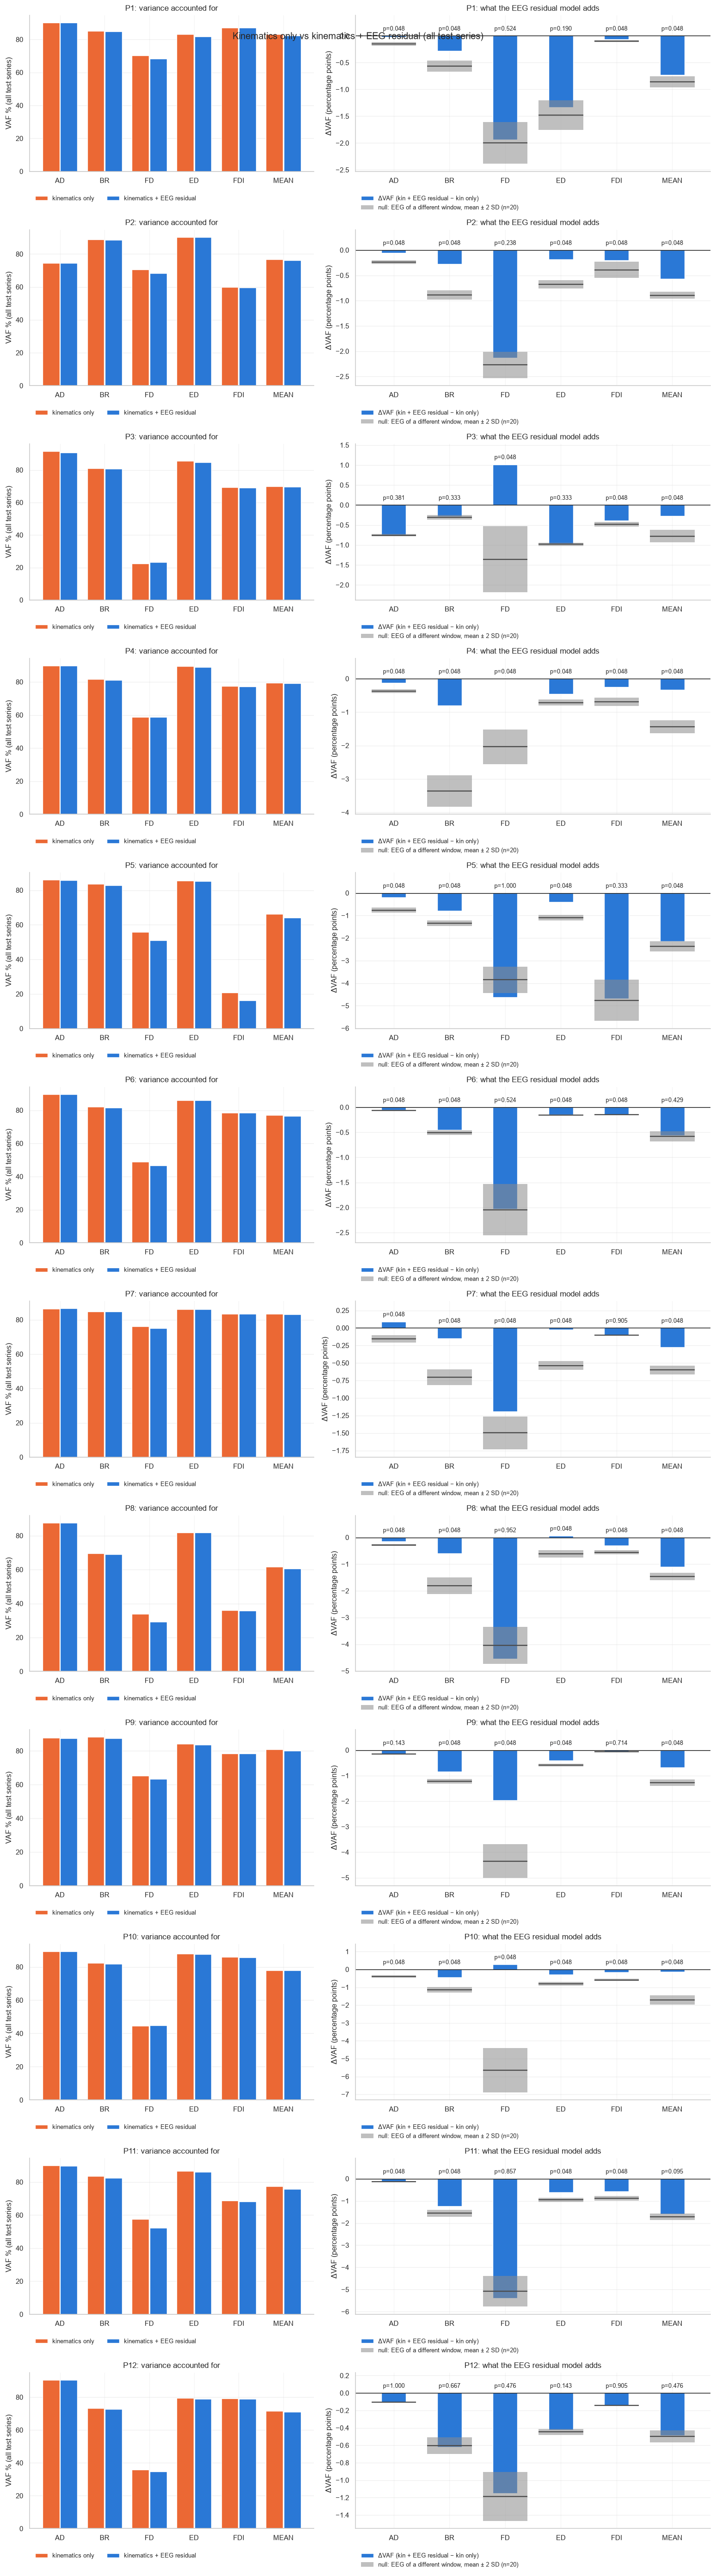

✓  Saved results/p2c/residual_delta_vaf.png


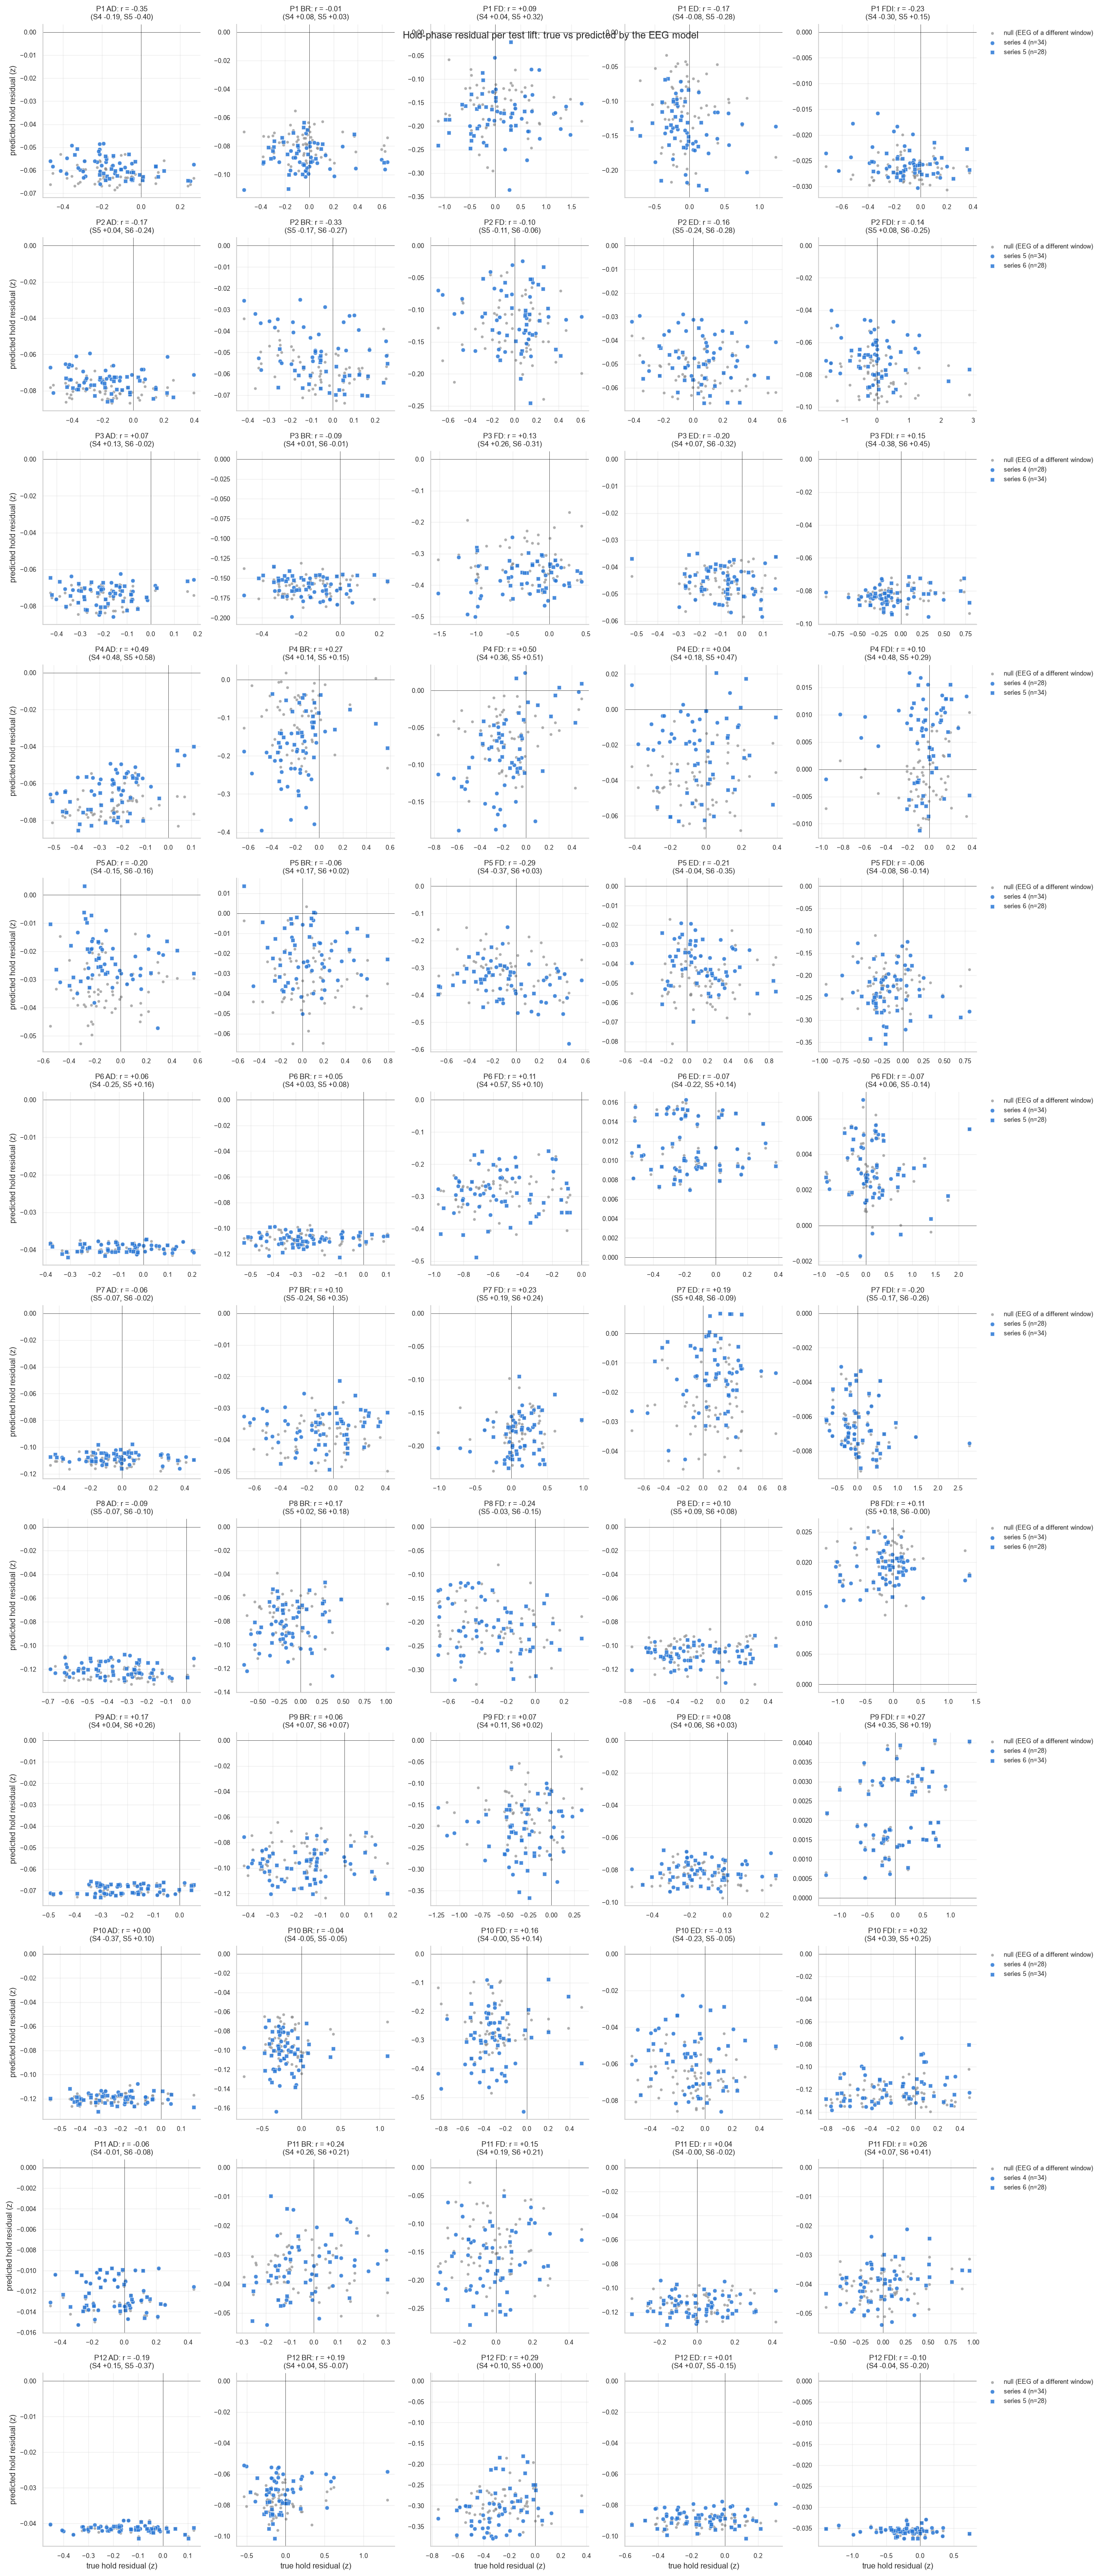

✓  Saved results/p2c/residual_per_lift.png

  VERDICT — does the EEG explain what the kinematics-only model leaves over?
  Rule: 'EEG adds unique information' only if ΔVAF > 0 AND p <= 0.05 against the window-swap null
        AND residual r > 0 in both test series (per lift in both, or per sample in both).
  P1 AD    no evidence                  ΔVAF -0.02 is not > 0
  P1 BR    no evidence                  ΔVAF -0.28 is not > 0
  P1 FD    no evidence                  ΔVAF -1.94 is not > 0; p = 0.524 > 0.05 against the window-swap null
  P1 ED    no evidence                  ΔVAF -1.33 is not > 0; p = 0.190 > 0.05 against the window-swap null
  P1 FDI   no evidence                  ΔVAF -0.07 is not > 0; residual r is not > 0 in every test series (neither per lift nor per sample)
  P1 MEAN  no evidence                  ΔVAF -0.73 is not > 0
  P2 AD    no evidence                  ΔVAF -0.05 is not > 0
  P2 BR    no evidence                  ΔVAF -0.28 is not > 0
  P2 FD    no evidence 

In [9]:
# ============================================================================
# RESIDUAL EVALUATION — what does the EEG residual model add on the test series?
# ============================================================================
# Test series only, 1 s windows through main.inference (same path as the other notebooks;
# the tail shorter than one window is dropped, like the test loader). Per muscle and MEAN,
# per test series and over all test series (main.residual_eval):
#   kin r / VAF / RMSE          kinematics-only model            (VAF, RMSE: original EMG units)
#   kin+EEG r / VAF / RMSE      kinematics-only prediction + predicted residual
#   ΔVAF, Δr                    (kin + EEG) − (kin only)
#   res r, res FVE              predicted vs true residual (z units); FVE can be negative
#   nulls (residual.n_null draws, seeded): the SAME EEG model with the EEG
#     shuffle = time-shuffled within each window (keeps the window's mean level)
#     swap    = taken from a DIFFERENT test window (random derangement of the test windows)
#     → mean ± SD of ΔVAF and res r under each null, p = (1 + #null >= observed) / (1 + n_null)
#   per lift: mean true vs mean predicted residual over the hold phase of every test lift
#     → Pearson r across lifts (per series, pooled, pooled after removing the series means),
#       and the same for the swap null
# Verdict per muscle (rules in the first cell): "EEG adds unique information" only if
#   ΔVAF > 0  AND  p <= 0.05 against the swap null  AND  residual r > 0 in both test series
#   (per lift in both, or per sample in both); otherwise "no evidence".
# Saves {RESULTS_DIR}/residual_report.csv, residual_per_lift.csv, residual_delta_vaf.png,
# residual_per_lift.png.
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from main import (
    get_split_series, series_conditions, lift_hold_segments,
    predict_residuals, residual_report, residual_verdict, format_residual_report,
    plot_residual_delta_vaf, plot_residual_per_lift,
)
from main.dataloader import emg_channel_names

RESIDUAL_CSV      = f"{RESULTS_DIR}/residual_report.csv"
RESIDUAL_LIFT_CSV = f"{RESULTS_DIR}/residual_per_lift.csv"
RESIDUAL_VAF_PNG  = f"{RESULTS_DIR}/residual_delta_vaf.png"
RESIDUAL_LIFT_PNG = f"{RESULTS_DIR}/residual_per_lift.png"


def evaluate_residual(subj, sd, kin_model, eeg_model, n_null, seed, max_windows=None):
    """Residual report of one subject's test series.

    max_windows: None = every test window (the result); an int keeps only the first
    max_windows windows of each test series (quick checks only).
    Returns (report, per_lift, verdict) — see main.residual_eval.
    """
    cfg = sd["cfg"]
    p_id = int(subj.lstrip("P"))
    test_ds = sd["test_ds"]
    window = cfg["dataset"]["window_size"]
    fs = cfg["data"].get("fs_eeg", 500.0)
    names = emg_channel_names(subj, test_ds.data_dir)      # true channel order, from the HS files

    # unique full series, in the dataset's (sorted) test-split order
    unique, seen = [], set()
    for _e, _k, _m, _start in test_ds._windows:
        if id(_e) not in seen:
            seen.add(id(_e))
            unique.append((_e, _k, _m))
    ids = get_split_series("test", p_id, test_ds.data_dir)
    assert len(ids) == len(unique), (ids, len(unique))
    if max_windows is not None:
        unique = [tuple(a[:max_windows * window] for a in arrays) for arrays in unique]
    series = dict(zip(ids, unique))

    preds = predict_residuals(
        kin_model, eeg_model, series, sd["prepare_batch"],
        window=window, device=device, n_null=n_null, seed=seed,
        batch_size=cfg["training"]["batch_size"],
    )
    segments = {
        sid: lift_hold_segments(p_id, sid, fs=fs, data_dir=test_ds.data_dir,
                                n_samples=len(preds.target[sid]))
        for sid in ids
    }
    report, per_lift = residual_report(preds, sd["emg_mean"], sd["emg_std"],
                                       channel_names=names, segments=segments)
    return report, per_lift, residual_verdict(report)


_res_cfg = notebook_cfg["residual"]
os.makedirs(RESULTS_DIR, exist_ok=True)
residual_reports, residual_lifts, residual_verdicts = {}, {}, {}

for _subj, _sd in subject_data.items():
    _report, _per_lift, _verdict = evaluate_residual(
        _subj, _sd, stage_k[_subj]["model"], stage_e[_subj]["model"],
        n_null=_res_cfg["n_null"], seed=_res_cfg["seed"],
    )
    residual_reports[_subj], residual_lifts[_subj], residual_verdicts[_subj] = _report, _per_lift, _verdict
    _conds = series_conditions(int(_subj.lstrip("P")), _sd["test_ds"].data_dir)
    print(f"\n{'─' * 100}\n  {_subj} — test series "
          + ", ".join(f"{_s} ({_conds.get(_s, '?')})" for _s in get_split_series(
              "test", int(_subj.lstrip("P")), _sd["test_ds"].data_dir))
          + f"\n{'─' * 100}")
    print(format_residual_report(_report))
    print(f"\n  Verdict per muscle [{_subj}]  (ΔVAF over all test series; p against the window-swap null; "
          f"residual r per test series)")
    for _, _v in _verdict.iterrows():
        print(f"    {_v['muscle']:<5} ΔVAF {_v['d_vaf']:+7.2f}   p {_v['p_swap']:.3f}   "
              f"res r [{_v['res_r_by_series']}]   lift r [{_v['lift_r_by_series']}]   "
              f"→ {_v['verdict']}   ({_v['why']})")

# ── tables ──────────────────────────────────────────────────────────────────
_rep_frames = []
for _subj, _report in residual_reports.items():
    _f = _report.copy()
    _f["verdict"] = ""
    _is_all = _f["group"] == "all test"
    _f.loc[_is_all, "verdict"] = _f.loc[_is_all, "muscle"].map(
        residual_verdicts[_subj].set_index("muscle")["verdict"])
    _f.insert(0, "subject", _subj)
    _rep_frames.append(_f)
residual_df = pd.concat(_rep_frames, ignore_index=True)
residual_df.to_csv(RESIDUAL_CSV, index=False)

_lift_frames = []
for _subj, _per_lift in residual_lifts.items():
    _f = _per_lift.copy()
    _f.insert(0, "subject", _subj)
    _lift_frames.append(_f)
residual_lift_df = pd.concat(_lift_frames, ignore_index=True)
residual_lift_df.to_csv(RESIDUAL_LIFT_CSV, index=False)
print(f"\n✓  Saved {RESIDUAL_CSV} and {RESIDUAL_LIFT_CSV}")

# ── figures ─────────────────────────────────────────────────────────────────
fig_res = plot_residual_delta_vaf(
    residual_reports, title="Kinematics only vs kinematics + EEG residual (all test series)")
fig_res.savefig(RESIDUAL_VAF_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓  Saved {RESIDUAL_VAF_PNG}")

if len(residual_lift_df):
    fig_lift = plot_residual_per_lift(
        residual_lift_df, title="Hold-phase residual per test lift: true vs predicted by the EEG model")
    fig_lift.savefig(RESIDUAL_LIFT_PNG, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"✓  Saved {RESIDUAL_LIFT_PNG}")
else:
    print("  No lift hold phase lies inside the evaluated samples: per-lift figure skipped.")

# ── verdict ─────────────────────────────────────────────────────────────────
print("\n" + "=" * 100)
print("  VERDICT — does the EEG explain what the kinematics-only model leaves over?")
print("  Rule: 'EEG adds unique information' only if ΔVAF > 0 AND p <= 0.05 against the window-swap null")
print("        AND residual r > 0 in both test series (per lift in both, or per sample in both).")
print("=" * 100)
for _subj, _verdict in residual_verdicts.items():
    for _, _v in _verdict.iterrows():
        print(f"  {_subj} {_v['muscle']:<5} {_v['verdict']:<28} {_v['why']}")
